In [2]:
import sys
from pathlib import Path

print("Python utilizado:", sys.executable)
print("Carpeta de trabajo:", Path.cwd())

Python utilizado: c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\.venv\Scripts\python.exe
Carpeta de trabajo: c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\F1


# Notebook de definición del problema y entorno reproducible — Fase 1

**Proyecto:** Caracterización de alojamientos Airbnb en Santiago de Chile

---

### ¿Qué produce la Fase 1?

La Fase 2 recibe un conjunto de datos y lo deja listo para modelar. Para que eso sea
posible, alguien tuvo que decidir antes **qué problema se resuelve, con qué datos y sobre
qué entorno**. Ese es el trabajo de la Fase 1, y el flujo de este cuaderno es:

**Definir → Configurar → Verificar → Estructurar → Documentar → Versionar**

Cada paso se implementa como una **función** reutilizable y termina en una **comprobación
con evidencia**. La diferencia con la Fase 2 es el objeto de trabajo: allá se transforman
datos, aquí se construye y se verifica el andamiaje que hace que esa transformación sea
reproducible por otra persona.

> **Lo que esta fase NO hace.** No limpia, no imputa, no codifica ni escala. Si en este
> cuaderno aparece una imputación, el trabajo está adelantado de fase y la rúbrica de la
> Fase 2 se queda sin evidencia propia.

## Introducción

Las plataformas de alojamiento temporal, como Airbnb, ofrecen
distintas alternativas de hospedaje en Santiago de Chile, con
características que varían según su ubicación, tipo de alojamiento,
capacidad, precio publicado y disponibilidad.

Conocer como se caracteriza este mercado permitirá que los usuarios puedan
incorporarse como anfitriones entendiendo cómo funciona la oferta existente.

El proyecto utilizará datos públicos de Inside Airbnb para
realizar una caracterización descriptiva de los alojamientos
publicados en Santiago de Chile.

**Objetivo general Fase 1:** Construir un flujo de trabajo reproducible y trazable 
que nos permita caracterizar la oferta existente de anuncios en Airbnb en la 
ciudad de Santiago de Chile. 

**Objetivos específicos Fase 1:**

- Declarar el problema, las preguntas que se responderán y los criterios de éxito.
- Verificar que el entorno de ejecución es el del proyecto y no el del sistema.
- Construir la estructura del repositorio y los artefactos que la hacen reproducible.
- Documentar la procedencia del conjunto de datos y evaluarla contra los criterios del curso.
- Dejar trazabilidad entre el mapa conceptual, el repositorio y este cuaderno.

### Herramientas del ecosistema científico

| Pieza | Para qué la usamos | Qué falla si se omite |
|---|---|---|
| Entorno virtual (`.venv`) | Aislar las versiones de las librerías del proyecto. | Un paquete «desaparece» o el compañero no puede reproducir. |
| JupyterLab + `ipykernel` | Ejecutar el cuaderno con el intérprete del proyecto. | `ModuleNotFoundError` con un paquete que sí está instalado. |
| `requirements.txt` | Declarar las dependencias exactas. | «A mí me funciona» y a nadie más. |
| Git | Registrar la historia del trabajo y su autoría. | No hay evidencia de contribución individual. |
| GitHub | Colaborar y publicar la evidencia evaluada. | El repositorio se convierte en un depósito de archivos. |
| `pathlib` | Rutas relativas independientes del sistema operativo. | `C:/Users/...` funciona en un solo computador del mundo. |

En esta fase se usan sobre todo módulos de la biblioteca estándar: el cuaderno construye y
verifica el entorno, todavía no analiza datos. `numpy` y `pandas` aparecen únicamente para
comprobar que están disponibles y para escribir las tablas de documentación.

In [3]:
import sys                        # intérprete en uso: es lo que se verifica más abajo
import json                       # exportación de metadatos legibles
import platform                   # sistema operativo, para dejarlo en la bitácora
import subprocess                 # consultas a Git desde el cuaderno
import shutil                     # localizar ejecutables (git) sin suponer que existen
import importlib                  # importar el módulo que este cuaderno va a escribir
import importlib.util             # comprobar si un paquete está instalado
from pathlib import Path          # manejo de rutas independiente del sistema operativo
from datetime import date

# Verificación del entorno: instala en el intérprete del kernel lo que falte.
print("Intérprete del kernel:", sys.executable)

REQUERIDOS = {"numpy": "numpy", "pandas": "pandas"}   # módulo: paquete pip
faltantes = [pkg for mod, pkg in REQUERIDOS.items()
             if importlib.util.find_spec(mod) is None]

if faltantes:
    print("Instalando:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])
    importlib.invalidate_caches()

import numpy as np                # presente para verificar el entorno del proyecto
import pandas as pd               # tablas de documentación de la fase

print("numpy", np.__version__, "· pandas", pd.__version__)

# Reproducibilidad: la misma semilla que usa el cuaderno de la Fase 2.
SEMILLA = 42
np.random.seed(SEMILLA)

print("Cuaderno de la Fase 1 ·", date.today().isoformat())

Intérprete del kernel: c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\.venv\Scripts\python.exe
numpy 2.5.4 · pandas 3.1.0
Cuaderno de la Fase 1 · 2026-11-10


## 1. Definición del problema

**Qué hace este paso.** Deja el problema escrito como una **estructura de datos**, no como
un párrafo suelto. Todo lo que el informe declara —problemática, objetivos, alcance,
criterios de éxito— queda aquí en un diccionario del que después se derivan el `README`,
los metadatos y la tabla de vinculación con el mapa conceptual.

**Por qué así.** Un dato escrito una sola vez no puede contradecirse consigo mismo. Si el
título del proyecto cambia, cambia en un lugar y se propaga a todos los artefactos. Es el
mismo principio que en la Fase 2 lleva a encapsular cada paso en una función en vez de
copiar y pegar.

In [18]:
PROYECTO = {
    "titulo": "Relación entre características de alojamientos frente a precios y niveles de ocupación en Airbnb",
    "grupo": "Grupo 8",
    "asignatura": "MCDI500 · Programación para la Ciencia de Datos",
    "integrantes": ["Giuliano Garces", "Ana Hermosilla", "Cristopher Contreras", "Gabriel Cruz"],
    "problematica": (
        "Los anfitriones de Airbnb desconocen cómo se relacionan ciertas "
        "caracterísiticas de los alojamientos frente al precio y niveles "
        "de ocupación. Acceder a esta información puede ser de utilidad para "
        "quienes ya cuenten con un alojamiento publicado o para quienes estén considerando "
        "entrar al mercado de Airbnb. Sin embargo, la información relevante se encuentra "
        "distribuida entre numerosos anuncios. Este proyecto busca "
        "organizar y describir dichas características mediante "
        "datos públicos de Airbnb en Santiago de Chile."
    ),
    "objetivo_general": (
        "Construir un flujo reproducible de análisis que, a partir de datos de alojamiento "
        "disponibles en Airbnb, permita relacionar los precios publicados y la disponibilidad de los alojamientos con sus características "
        "en Santiago de Chile."
    ),
    "objetivos_especificos": [
        "Definir el problema y verificar el entorno reproducible (F1).",
        "Identificar y clasificar las variables relevantes del dataset.",
        "Explorar, limpiar y transformar los datos con criterios "
        "técnicos justificados (F2).",
        "Describir la distribución de alojamientos según ubicación, "
        "precio publicado, tipo, capacidad y disponibilidad."
    ],
    "preguntas": [
        "¿Qué características poseen los alojamientos de Airbnb "
        "en Santiago de Chile que puedan ser útiles para "
        "los anfitriones actuales y nuevos?",

        "¿Cómo se distribuyen territorialmente los alojamientos?",

        "¿Cómo varían los precios y niveles de ocupación publicados según las "
        "características de los alojamientos?",

        "¿Qué diferencias existen en capacidad, tipo de "
        "alojamiento y disponibilidad publicada?"
    ],
    "criterios_exito": [
        "El repositorio se clona y el cuaderno corre completo sin intervención manual.",
        "Cada decisión de preprocesamiento queda justificada con cifras, no con adjetivos.",
        "Los cuatro integrantes tienen commits propios en el historial.",
    ],
    "alcance": {
        "incluye": ["Definición del problema",
            "Entorno reproducible",
            "Caracterización descriptiva",
            "Exploración y procesamiento de datos"],
        "excluye": ["Predicción de rentabilidad",
            "Estimación de ingresos reales",
            "Modelado predictivo",
            "Recomendaciones de inversión garantizada"],
    },
    "limitaciones": [
        "Los datos corresponden a información secundaria publicada.",
        "Los precios anunciados no representan necesariamente "
        "los precios efectivamente pagados.",
        "La disponibilidad del calendario no equivale "
        "directamente a ocupación real.",
        "Los resultados describen el período cubierto "
        "por el dataset y no necesariamente el mercado futuro."
    ],
}

La función siguiente presenta el proyecto en pantalla. Recibe el diccionario como
parámetro en vez de leer la variable global: así puede reutilizarse con la configuración de
cualquier grupo y probarse de forma aislada.

In [19]:
def presentar_proyecto(config):
    """
    Imprime la definicion del proyecto de forma legible.

    Parametros
    ----------
    config : dict
        Diccionario de configuracion del proyecto.

    Retorna
    -------
    None

    Lanza
    -----
    KeyError
        Si falta alguna de las claves obligatorias.
    """
    obligatorias = ("titulo", "problematica", "objetivo_general", "objetivos_especificos")
    faltantes = [c for c in obligatorias if c not in config]
    if faltantes:
        # Se falla temprano y con un mensaje que dice QUE falta, no solo que algo falló.
        raise KeyError(f"Faltan claves obligatorias en la configuracion: {faltantes}")

    print(config["titulo"].upper())
    print("=" * 60)
    print(f"{config['asignatura']} · {config['grupo']}")
    print("\nProblemática")
    print(config["problematica"])
    print("\nObjetivo general")
    print(config["objetivo_general"])
    print("\nObjetivos específicos")
    for i, obj in enumerate(config["objetivos_especificos"], start=1):
        print(f"  {i}. {obj}")
    print("\nPreguntas que orientan el trabajo")
    for pregunta in config["preguntas"]:
        print(f"  · {pregunta}")


presentar_proyecto(PROYECTO)

RELACIÓN ENTRE CARACTERÍSTICAS DE ALOJAMIENTOS FRENTE A PRECIOS Y NIVELES DE OCUPACIÓN EN AIRBNB
MCDI500 · Programación para la Ciencia de Datos · Grupo 8

Problemática
Los anfitriones de Airbnb desconocen cómo se relacionan ciertas caracterísiticas de los alojamientos frente al precio y niveles de ocupación. Acceder a esta información puede ser de utilidad para quienes ya cuenten con un alojamiento publicado o para quienes estén considerando entrar al mercado de Airbnb. Sin embargo, la información relevante se encuentra distribuida entre numerosos anuncios. Este proyecto busca organizar y describir dichas características mediante datos públicos de Airbnb en Santiago de Chile.

Objetivo general
Construir un flujo reproducible de análisis que, a partir de datos de alojamiento disponibles en Airbnb, permita relacionar los precios publicados y la disponibilidad de los alojamientos con sus características en Santiago de Chile.

Objetivos específicos
  1. Definir el problema y verificar el 

El alcance y las limitaciones se presentan aparte porque cumplen una función distinta:
delimitan lo que **no** se hará. Es lo que evita que el informe de la Fase 4 sea juzgado
por algo que nunca estuvo comprometido.

In [6]:
print("Alcance de la Fase 1")
print("  Incluye:", ", ".join(PROYECTO["alcance"]["incluye"]))
print("  Excluye:", ", ".join(PROYECTO["alcance"]["excluye"]))

print("\nLimitaciones declaradas")
for lim in PROYECTO["limitaciones"]:
    print(f"  · {lim}")

Alcance de la Fase 1
  Incluye: Definición del problema, Entorno reproducible, Caracterización descriptiva, Exploración y procesamiento de datos
  Excluye: Predicción de rentabilidad, Estimación de ingresos reales, Modelado predictivo, Recomendaciones de inversión garantizada

Limitaciones declaradas
  · Los datos corresponden a información secundaria publicada.
  · Los precios anunciados no representan necesariamente los precios efectivamente pagados.
  · La disponibilidad del calendario no equivale directamente a ocupación real.
  · Los resultados describen el período cubierto por el dataset y no necesariamente el mercado futuro.


> **Sobre las limitaciones.** Declararlas antes de haber analizado nada es señal de
> comprensión del problema, no de debilidad del trabajo. La alternativa —descubrirlas al
> final y omitirlas— es la que la rúbrica penaliza.

## 2. Verificación del entorno

**Qué hace este paso.** Comprueba, con evidencia y no por confianza, que el cuaderno se
está ejecutando con el intérprete del proyecto y que las librerías declaradas están
disponibles en él.

**Por qué es la primera comprobación del proyecto.** Los dos errores más frecuentes del
módulo —un paquete que «desaparece» y un `ModuleNotFoundError` con una librería que sí se
instaló— no son errores de código: son el entorno o el kernel equivocados. Verificarlo
cuesta tres segundos y ahorra horas de diagnóstico sobre el archivo equivocado.

In [7]:
DEPENDENCIAS = ["numpy", "pandas", "matplotlib", "sklearn"]

# Correspondencia entre el nombre de importación y el nombre del paquete en PyPI:
# se instala scikit-learn, pero se importa sklearn.
NOMBRE_EN_PYPI = {"sklearn": "scikit-learn"}


def verificar_entorno(dependencias):
    """
    Comprueba interprete, entorno virtual, carpeta de trabajo y librerias.

    Parametros
    ----------
    dependencias : list of str
        Nombres de importacion de las librerias que el proyecto declara.

    Retorna
    -------
    dict
        Resultado de cada comprobacion, para dejarlo en la bitacora de la fase.
    """
    reporte = {}

    # 1. Intérprete que ejecuta ESTE cuaderno. Si la ruta no contiene .venv,
    #    el kernel no es el del proyecto: Kernel -> Change Kernel.
    ejecutable = Path(sys.executable)
    en_venv = ".venv" in ejecutable.parts or sys.prefix != sys.base_prefix
    reporte["interprete"] = str(ejecutable)
    reporte["entorno_virtual"] = bool(en_venv)
    print("Intérprete       :", ejecutable)
    print("Entorno virtual  :", "[OK] activo" if en_venv else "[AVISO] parece el Python del sistema")

    # 2. Carpeta de trabajo: las rutas relativas se resuelven desde aquí,
    #    no desde donde está guardado el archivo .ipynb.
    reporte["carpeta_trabajo"] = str(Path.cwd())
    print("Carpeta de trabajo:", Path.cwd())
    print("Sistema          :", platform.system(), platform.release())
    print("Python           :", sys.version.split()[0])

    # 3. Librerías del proyecto, con su versión.
    print("\nLibrerías declaradas")
    versiones = {}
    for nombre in dependencias:
        try:
            modulo = importlib.import_module(nombre)
            version = getattr(modulo, "__version__", "sin atributo __version__")
            versiones[nombre] = version
            print(f"  [OK]    {nombre:12} {version}")
        except ImportError:
            # No se interrumpe el cuaderno: se informa qué instalar y con qué nombre.
            versiones[nombre] = None
            paquete = NOMBRE_EN_PYPI.get(nombre, nombre)
            print(f"  [FALTA] {nombre:12} instale con: python -m pip install {paquete}")
    reporte["versiones"] = versiones
    return reporte


ENTORNO = verificar_entorno(DEPENDENCIAS)

Intérprete       : c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\.venv\Scripts\python.exe
Entorno virtual  : [OK] activo
Carpeta de trabajo: c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\F1
Sistema          : Windows 11
Python           : 3.13.16

Librerías declaradas
  [OK]    numpy        2.5.4
  [OK]    pandas       3.1.0
  [OK]    matplotlib   3.11.2
  [OK]    sklearn      1.9.1


**Cómo se lee este resultado.** Cada línea corresponde a uno de los acoplamientos que la
guía de Git y GitHub describe en su Parte II:

| Lo que ve | Qué significa | Qué hacer |
| --- | --- | --- |
| El intérprete no contiene `.venv` | El kernel no es el del proyecto | *Kernel → Change Kernel* |
| Una librería aparece como `[FALTA]` | Se instaló fuera del entorno | Active el entorno y reinstale |
| La carpeta de trabajo es `F1` o `F2` | Es lo normal: Jupyter abre el kernel en la carpeta del cuaderno | Nada: la sección 3 localiza la raíz del proyecto |

> **Recomendación.** Deje esta celda como primera celda de todos sus cuadernos, también en
> las fases siguientes. Responde de inmediato la pregunta «¿el problema es mi código o mi
> entorno?», que es la que más tiempo consume cuando no se responde a tiempo.

## 3. Estructura del repositorio y artefactos

**Qué hace este paso.** Crea las carpetas del proyecto y escribe desde el cuaderno los dos
archivos que hacen reproducible el entorno: `.gitignore` y `requirements.txt`.

**Por qué desde el cuaderno.** Porque así quedan derivados de la configuración declarada en
la sección 1 y no de lo que alguien recordó escribir a mano. Es la misma lógica de la Fase
2: el artefacto se genera, se verifica y queda trazado.

In [8]:
def localizar_raiz(inicio=None):
    """
    Devuelve la raíz del proyecto.

    Jupyter abre el kernel en la carpeta donde está guardado el cuaderno, no en la
    carpeta desde la que se lanzó JupyterLab. Como cada cuaderno vive en la carpeta
    de su fase (F1, F2, F3 o F4), si la carpeta de trabajo es una de ellas la raíz
    es la carpeta superior. Si el cuaderno se ejecuta desde la raíz, se usa tal cual.
    """
    inicio = Path.cwd() if inicio is None else Path(inicio)
    return inicio.parent if inicio.name in {"F1", "F2", "F3", "F4"} else inicio


RAIZ = localizar_raiz()

# Rutas de datos COMUNES a todas las fases: son exactamente las que usa el
# cuaderno de la Fase 2, de modo que un mismo archivo sirva a los dos.
DIR_CRUDO = RAIZ / "data" / "raw"          # datos originales: nunca se modifican
DIR_PROCESADO = RAIZ / "data" / "processed"  # salida del pipeline de la Fase 2
DIR_DOCS = RAIZ / "docs"                   # diccionario, fichas y metadatos
DIR_SRC = RAIZ / "src"                     # módulos propios reutilizables

# Una carpeta por fase para cuadernos e informes.
DIR_FASES = [RAIZ / f"F{n}" for n in (1, 2, 3, 4)]

for carpeta in [DIR_CRUDO, DIR_PROCESADO, DIR_DOCS, DIR_SRC, *DIR_FASES]:
    # parents=True crea las intermedias; exist_ok=True evita el error si ya existen,
    # que es lo que permite volver a ejecutar el cuaderno completo sin romperlo.
    carpeta.mkdir(parents=True, exist_ok=True)

print("Estructura creada bajo:", RAIZ.resolve())
# Se omiten las carpetas ocultas (.git, .venv, .ipynb_checkpoints) y las cachés.
for ruta in sorted(p.relative_to(RAIZ) for p in RAIZ.rglob("*") if p.is_dir()):
    if any(parte.startswith(".") or parte == "__pycache__" for parte in ruta.parts):
        continue
    print("  ", ruta.as_posix() + "/")

Estructura creada bajo: C:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500
   data/
   data/processed/
   data/raw/
   docs/
   F1/
   F2/
   F3/
   F4/
   src/


> **Decisión que el grupo debe tomar y documentar.** La guía de desarrollo propone una
> variante en que cada fase tiene su propia carpeta `data/`. Aquí los datos son comunes a
> todas las fases y solo los cuadernos e informes se separan por fase, que es lo que
> supone el cuaderno de la Fase 2 al escribir `data/raw`. Cualquiera de las dos opciones
> sirve; lo que no puede ocurrir es que cada cuaderno suponga una ruta distinta. Si
> cambian de opción, cámbienla en los dos cuadernos a la vez y déjenlo escrito en el
> `README`.

In [8]:
print("Raíz del proyecto:", RAIZ)
print("Dataset encontrado:", (DIR_CRUDO / "datasetairbnb.csv").exists())
print("Diccionario encontrado:", (DIR_DOCS / "diccionario_variables.csv").exists())


Raíz del proyecto: c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500
Dataset encontrado: True
Diccionario encontrado: True


### 3.1 El archivo `.gitignore`

Quedan fuera del repositorio tres cosas: lo que se regenera (el entorno virtual, las
cachés), lo que es local de cada equipo (archivos del sistema operativo) y lo que es
secreto (credenciales). Se escribe **antes** del primer `git add .`: después ya es tarde,
porque el archivo quedó en el historial.

In [ ]:
CONTENIDO_GITIGNORE = """# Entorno virtual: se reconstruye con requirements.txt
.venv/

# Caché de Python
__pycache__/
*.pyc

# Jupyter
.ipynb_checkpoints/

# Windows
Thumbs.db
desktop.ini

# macOS
.DS_Store

# Variables de entorno y secretos
.env

# Datos pesados y modelos
*.ckpt
*.pth

# Datos originales excluidos por contener informacion personal
data/raw/*
!data/raw/.gitkeep

"""

ARCHIVO_GITIGNORE = RAIZ / ".gitignore"
ARCHIVO_GITIGNORE.write_text(CONTENIDO_GITIGNORE, encoding="utf-8")

# Verificación de ida y vuelta: se relee lo escrito antes de darlo por hecho.
lineas = [l for l in ARCHIVO_GITIGNORE.read_text(encoding="utf-8").splitlines()
          if l and not l.startswith("#")]
assert ".venv/" in lineas, "El entorno virtual debe estar ignorado."
print(f"{ARCHIVO_GITIGNORE} escrito con {len(lineas)} reglas activas.")

c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\.gitignore escrito con 10 reglas activas.


> **Atención — los datos.** Este `.gitignore` **no** ignora `data/`. Si el conjunto es
> liviano, versionarlo facilita que cualquiera reproduzca el análisis y es lo preferible
> para este curso; si supera unas decenas de MB, agréguenlo aquí y documenten en el
> `README` de dónde se descarga y en qué carpeta va. GitHub rechaza archivos sobre 100 MB.

### 3.2 El archivo `requirements.txt`

Declarar las dependencias es lo que separa «funciona en mi computador» de un entorno
reproducible. Se escriben con la versión exacta observada en el entorno, no con la última
que exista en el momento de instalar.

Decisión técnica respecto a la gestión de dependencias:

El proyecto utiliza un archivo requirements.txt previamente generado mediante pip freeze y versionado en GitHub. Este contiene las dependencias directas e indirectas del entorno.

La sección 3.2 se adaptó para verificar la existencia del archivo y la correspondencia de sus dependencias principales con las versiones instaladas, sin sobrescribirlo.

Cada integrante deberá construir su propio entorno virtual utilizando python -m pip install -r requirements.txt, decisión que favorece la reproducibilidad y evita la modificación involuntaria de las dependencias compartidas. 

In [14]:
def escribir_requirements(ruta, versiones):
    """
    Escribe requirements.txt a partir de las versiones observadas en el entorno.

    Parametros
    ----------
    ruta : Path
        Archivo de salida.
    versiones : dict
        Nombre de importacion -> version detectada (o None si falta).

    Retorna
    -------
    list of str
        Lineas escritas, para verificarlas.

    Lanza
    -----
    ValueError
        Si ninguna dependencia pudo detectarse.
    """
    lineas = []
    for nombre, version in versiones.items():
        if version is None:
            continue  # una librería ausente no se declara: primero se instala
        paquete = NOMBRE_EN_PYPI.get(nombre, nombre)
        lineas.append(f"{paquete}=={version}")

    if not lineas:
        raise ValueError("No se detectó ninguna dependencia instalada.")

    # Se agregan las herramientas del flujo de trabajo, que no se importan
    # desde el código pero sí forman parte del entorno reproducible.
    lineas += ["jupyterlab", "notebook", "ipykernel"]
    ruta.write_text("\n".join(sorted(lineas)) + "\n", encoding="utf-8")
    return sorted(lineas)



# Archivo de dependencias compartido por el equipo
ARCHIVO_REQUIREMENTS = RAIZ / "requirements.txt"

# 1. Comprobar que el archivo existe
assert ARCHIVO_REQUIREMENTS.exists(), (
    "No se encontró requirements.txt en la raíz del proyecto."
)

# 2. Leer su contenido sin modificarlo
requisitos = [
    linea.strip()
    for linea in ARCHIVO_REQUIREMENTS.read_text(
        encoding="utf-8"
    ).splitlines()
    if linea.strip() and not linea.lstrip().startswith("#")
]

# Preparar las dependencias para compararlas
requisitos_normalizados = {
    requisito.lower() for requisito in requisitos
}

# 3. Comprobar las versiones de las librerías instaladas
print("VERIFICACIÓN DE DEPENDENCIAS")
print("-" * 40)

for nombre, version in ENTORNO["versiones"].items():

    assert version is not None, (
        f"La librería {nombre} no está instalada."
    )

    paquete = NOMBRE_EN_PYPI.get(nombre, nombre)
    dependencia = f"{paquete}=={version}"

    assert dependencia.lower() in requisitos_normalizados, (
        f"Dependencia ausente o versión diferente: {dependencia}"
    )

    print(f"[OK] {dependencia}")

# 4. Comprobar las herramientas de Jupyter
for paquete in ["jupyterlab", "notebook", "ipykernel"]:

    encontrado = any(
        requisito.startswith(f"{paquete}==")
        for requisito in requisitos_normalizados
    )

    assert encontrado, f"Falta declarar {paquete}"

    print(f"[OK] {paquete} declarado")

print("\nrequirements.txt verificado sin modificaciones.")


VERIFICACIÓN DE DEPENDENCIAS
----------------------------------------
[OK] numpy==2.5.4
[OK] pandas==3.1.0
[OK] matplotlib==3.11.2
[OK] scikit-learn==1.9.1
[OK] jupyterlab declarado
[OK] notebook declarado
[OK] ipykernel declarado

requirements.txt verificado sin modificaciones.


In [13]:
print("RUTA DEL ARCHIVO:")
print(ARCHIVO_REQUIREMENTS.resolve())

print("\nCONTENIDO ACTUAL EN DISCO:")
print([
    linea
    for linea in ARCHIVO_REQUIREMENTS.read_text(
        encoding="utf-8"
    ).splitlines()
    if "notebook" in linea.lower()
])

print("\nCONTENIDO GUARDADO EN MEMORIA:")
print([
    linea
    for linea in requisitos
    if "notebook" in linea.lower()
])

RUTA DEL ARCHIVO:
C:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\requirements.txt

CONTENIDO ACTUAL EN DISCO:
['notebook==7.6.4']

CONTENIDO GUARDADO EN MEMORIA:
[]


## 4. Módulos: del cuaderno a `src/`

**Qué hace este paso.** Escribe un módulo `src/utilidades.py` y lo importa de vuelta.

**Por qué.** La Unidad 1 pide funciones, excepciones **y módulos**. Un cuaderno documenta y
comunica; un módulo es lo que permite que la misma función se use en las cuatro fases sin
copiarla. Aquí se mueve una función pequeña pero real: la que normaliza los nombres de las
columnas, que las fases siguientes usarán apenas carguen datos.

In [11]:
CODIGO_MODULO = """\
\"\"\"Utilidades compartidas del proyecto MCDI500 - Grupo X.

Este modulo lo genera el cuaderno de la Fase 1 y lo importan las fases siguientes.
\"\"\"

import re


class ProyectoError(Exception):
    \"\"\"Error propio del proyecto: permite distinguirlo de los de las librerias.\"\"\"


def normalizar_nombre(texto):
    \"\"\"Convierte un nombre de columna a minusculas, sin espacios ni signos.

    Ejemplo
    -------
    >>> normalizar_nombre('Residence Type ')
    'residence_type'
    \"\"\"
    if not isinstance(texto, str):
        raise ProyectoError(f\"Se esperaba texto y se recibio {type(texto).__name__}.\")
    limpio = texto.strip().lower()
    limpio = re.sub(r\"[^a-z0-9]+\", \"_\", limpio)   # todo lo que no sea letra o digito -> _
    return limpio.strip(\"_\")


def normalizar_columnas(nombres):
    \"\"\"Aplica normalizar_nombre a una lista y verifica que no se produzcan duplicados.\"\"\"
    normalizados = [normalizar_nombre(n) for n in nombres]
    if len(set(normalizados)) != len(normalizados):
        raise ProyectoError(\"La normalizacion produjo nombres duplicados.\")
    return normalizados
"""

ARCHIVO_MODULO = DIR_SRC / "utilidades.py"
ARCHIVO_MODULO.write_text(CODIGO_MODULO, encoding="utf-8")
print("Módulo escrito en:", ARCHIVO_MODULO)

Módulo escrito en: c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\src\utilidades.py


Para importarlo hay que agregar `src/` a la lista de rutas donde Python busca módulos.
`invalidate_caches()` es necesario porque el archivo se acaba de crear: sin esa llamada,
Python puede no ver un módulo escrito después de arrancar el intérprete.

In [12]:
if str(DIR_SRC.resolve()) not in sys.path:
    sys.path.insert(0, str(DIR_SRC.resolve()))

importlib.invalidate_caches()
import utilidades                      # el módulo recién escrito
importlib.reload(utilidades)           # por si el cuaderno se vuelve a ejecutar

print("Importado:", utilidades.__name__, "desde", Path(utilidades.__file__).as_posix())
print(utilidades.normalizar_nombre("Residence Type "))
print(utilidades.normalizar_columnas(["Avg Glucose Level", "BMI", "smoking status"]))

Importado: utilidades desde C:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/src/utilidades.py
residence_type
['avg_glucose_level', 'bmi', 'smoking_status']


### 4.1 Pruebas del módulo (casos normal, límite y excepción)

Las mismas tres categorías que exige la rúbrica en la Fase 2 se aplican aquí. `assert`
detiene el cuaderno si una condición no se cumple, dejando constancia de la falla en la
salida ejecutada.

In [13]:
# --- Caso normal ---
assert utilidades.normalizar_nombre("Avg Glucose Level") == "avg_glucose_level"
assert utilidades.normalizar_columnas(["A B", "c-d"]) == ["a_b", "c_d"]
print("[OK] Caso normal: normalización correcta")

# --- Caso límite: signos consecutivos y espacios en los extremos ---
assert utilidades.normalizar_nombre("  ¿BMI (kg/m2)?  ") == "bmi_kg_m2"
assert utilidades.normalizar_columnas([]) == []
print("[OK] Caso límite: signos y lista vacía")

# --- Excepción 1: tipo incorrecto ---
try:
    utilidades.normalizar_nombre(42)
except utilidades.ProyectoError as e:
    print(f"[OK] Excepción capturada (tipo): {e}")

# --- Excepción 2: la normalización colapsa dos nombres en uno ---
# "BMI" y " bmi " producen ambos "bmi": el módulo lo detecta en vez de perder una columna.
try:
    utilidades.normalizar_columnas(["BMI", " bmi "])
except utilidades.ProyectoError as e:
    print(f"[OK] Excepción capturada (duplicados): {e}")

[OK] Caso normal: normalización correcta
[OK] Caso límite: signos y lista vacía
[OK] Excepción capturada (tipo): Se esperaba texto y se recibio int.
[OK] Excepción capturada (duplicados): La normalizacion produjo nombres duplicados.


> **Por qué una excepción propia.** `ProyectoError` hereda de `Exception` y permite
> distinguir un fallo del proyecto de uno de pandas o de scikit-learn. Cuando el cuaderno
> de la Fase 3 capture errores, podrá tratar de forma distinta «los datos venían mal» y
> «mi función recibió lo que no esperaba».

## 5. Selección y ficha del conjunto de datos

**Qué hace este paso.** Documenta la procedencia del conjunto y la evalúa contra los
criterios de selección del curso.

**Por qué en la Fase 1.** Porque la elección del conjunto condiciona todo lo que viene
después. Un conjunto ya limpio convierte la sección de preprocesamiento de la Fase 2 en un
trámite y hace perder el criterio de mayor peso de la Sumativa 1.

### 5.1 Procedencia

| Campo | Valor |
| --- | --- |
| Título | Inside Airbnb - Santiago, Chile |
| Autor | Murray Cox (Inside Airbnb) |
| Plataforma | Inside Airbnb |
| Enlace | `https://data.insideairbnb.com/chile/rm/santiago/2026-09-23/data/listings.csv.gz` |
| Estructura esperada | 18.904 filas × 90 columnas` |
| Unidad de observación | Un anuncio de alojamiento (listing) en Airbnb |
| Licencia | Abierta, Creative Commons Attribution 4.0 International (CC BY 4.0) |

**Referencia:**

Cox, M. (2026). Inside Airbnb - Santiago, Chile (Versión 23 de septiembre de 2026) [Conjunto de datos]. Inside Airbnb. https://data.insideairbnb.com/chile/rm/santiago/2026-09-23/data/listings.csv.gz


In [14]:
FICHA = {
    "titulo": "Inside Airbnb - Santiago, Chile",
    "autor": "Murray Cox (Inside Airbnb)",
    "plataforma": "Inside Airbnb",
    "url": "https://data.insideairbnb.com/chile/rm/santiago/2026-09-23/data/listings.csv.gz",
    "licencia_abierta": True,
    "unidad_observacion": "Un anuncio de alojamiento",
    "filas": 18904,
    "columnas": 90,
    "tamano_mb": 45.0, # Valor aproximado descomprimido, ajústalo al descargarlo
    "roles": {
        "continua": 16,          # price, review_scores_rating, reviews_per_month, latitude, longitude
        "discreta": 28,          # accommodates, bedrooms, beds, number_of_reviews, estimated_occupancy_l365d
        "binaria": 4,           # host_is_superhost, host_identity_verified, has_availability, instant_bookable
        "nominal": 5,           # neighbourhood_cleansed, property_type, room_type, host_response_time
        "ordinal": 0,
        "fecha": 6,             # host_since, first_review, last_review
        "alta_cardinalidad": 8, # name, description, amenities
        "identificador": 9,     # id, host_id
    },
    "columnas_sin_datos": 14,
    "pct_nulos_max_variable": 100,  # Valor de ejemplo a verificar en EDA (suele ser alto en reviews o licencias)
    "pct_nulos_min_no_cero": 1.0,    # Valor de ejemplo a verificar en EDA
}

Se actualizan los datos de FICHA con calculos actualizados directamentes desde el dataset original:

In [15]:

ARCHIVO = DIR_CRUDO / "datasetairbnb.csv"

# Comprobar que el archivo existe
assert ARCHIVO.exists(), (
    f"No se encontró el dataset: {ARCHIVO}"
)

# Cargar los datos originales
df_ficha = pd.read_csv(ARCHIVO, low_memory=False)

# Verificar las dimensiones declaradas en FICHA
assert df_ficha.shape == (
    FICHA["filas"],
    FICHA["columnas"]
), "Las dimensiones reales no coinciden con FICHA."

# Calcular los porcentajes de valores faltantes
porcentajes_nulos = df_ficha.isna().mean() * 100

# Seleccionar las variables que tienen al menos un dato faltante
porcentajes_con_nulos = porcentajes_nulos[
    porcentajes_nulos > 0
]

# Actualizar los indicadores de FICHA
FICHA["tamano_mb"] = round(
    ARCHIVO.stat().st_size / (1024 ** 2), 2
)

FICHA["columnas_sin_datos"] = int(
    (porcentajes_nulos == 100).sum()
)

FICHA["pct_nulos_max_variable"] = float(
    porcentajes_nulos.max()
)

FICHA["pct_nulos_min_no_cero"] = (
    float(porcentajes_con_nulos.min())
    if not porcentajes_con_nulos.empty
    else 0.0
)

print("[OK] Ficha técnica actualizada")
print("Tamaño del CSV (MiB):", FICHA["tamano_mb"])
print("Columnas completamente vacías:", FICHA["columnas_sin_datos"])
print("Mayor porcentaje de nulos:", FICHA["pct_nulos_max_variable"])
print("Menor porcentaje no nulo:", FICHA["pct_nulos_min_no_cero"])

[OK] Ficha técnica actualizada
Tamaño del CSV (MiB): 49.8
Columnas completamente vacías: 14
Mayor porcentaje de nulos: 100.0
Menor porcentaje no nulo: 0.026449428692340245


### 5.2 Evaluación contra los criterios del curso

La función compara la ficha con los mínimos definidos para el proyecto y devuelve una
tabla con el veredicto por criterio. No decide por el grupo: expone lo que falta.

In [16]:
# Requisitos del curso. Los OBLIGATORIOS descalifican el conjunto si no se cumplen;
# los AVISOS no lo descalifican, pero lo que falte se declara en el informe como
# restricción del conjunto. Son los mismos que aplica validar_dataset.py.
OBLIGATORIOS = {
    "filas": ("Filas", 2000, "Permite agrupar por categoría sin grupos vacíos"),
    "columnas": ("Columnas", 12, "Asegura variedad de roles analíticos"),
    "roles": ("Roles analíticos distintos", 3, "El conjunto debe ser multivariado"),
    "numerica": ("Variables numéricas", 1, "Escalamiento y valores atípicos"),
    "categorica": ("Variables categóricas", 1, "Codificación de categorías"),
}
AVISOS = {
    "fecha": ("Fecha", 1, "Parseo y derivación de variables temporales"),
    "alta_cardinalidad": ("Texto o alta cardinalidad", 1, "Normalización y agrupación"),
}

# Roles que cuentan para cada grupo. El identificador no es un rol analítico:
# no se analiza, solo distingue filas.
NUMERICOS = ("continua", "discreta")
CATEGORICOS = ("binaria", "nominal", "ordinal")


def evaluar_criterios(ficha, obligatorios=OBLIGATORIOS, avisos=AVISOS):
    """
    Compara una ficha de conjunto de datos con los requisitos del curso.

    Parametros
    ----------
    ficha : dict
        Ficha del conjunto, con las claves 'filas', 'columnas' y 'roles'.
    obligatorios, avisos : dict
        Criterio -> (etiqueta, minimo, motivo).

    Retorna
    -------
    pd.DataFrame
        Una fila por criterio, con su tipo, el valor observado y el veredicto.

    Lanza
    -----
    KeyError
        Si la ficha no declara los roles analiticos.
    """
    if "roles" not in ficha:
        raise KeyError("La ficha debe declarar el conteo de variables por rol analítico.")

    roles = ficha["roles"]
    observado = {
        "filas": ficha.get("filas", 0),
        "columnas": ficha.get("columnas", 0),
        # Cuántos roles distintos aparecen al menos una vez, sin contar el identificador.
        "roles": sum(1 for rol, n in roles.items() if n > 0 and rol != "identificador"),
        "numerica": sum(roles.get(r, 0) for r in NUMERICOS),
        "categorica": sum(roles.get(r, 0) for r in CATEGORICOS),
        "fecha": roles.get("fecha", 0),
        "alta_cardinalidad": roles.get("alta_cardinalidad", 0),
    }

    filas = []
    for tipo, criterios in (("obligatorio", obligatorios), ("aviso", avisos)):
        for clave, (etiqueta, minimo, motivo) in criterios.items():
            valor = observado[clave]
            # Un aviso incumplido no dice NO: dice que hay algo que declarar.
            falla = "NO" if tipo == "obligatorio" else "aviso"
            filas.append({
                "criterio": etiqueta,
                "tipo": tipo,
                "mínimo": minimo,
                "observado": valor,
                "cumple": "sí" if valor >= minimo else falla,
                "por qué se pide": motivo,
            })

    # Los faltantes se informan como aviso: un conjunto sin ellos se puede usar,
    # pero deja con poca evidencia la sección de preprocesamiento de la Fase 2.
    pct = ficha.get("pct_nulos_max_variable", 0.0)
    filas.append({
        "criterio": "Alguna variable con ≥1% de nulos", "tipo": "aviso",
        "mínimo": 1.0, "observado": pct,
        "cumple": "sí" if pct >= 1.0 else "aviso",
        "por qué se pide": "Un conjunto perfecto no tiene preprocesamiento que justificar",
    })
    pct_max = ficha.get("pct_nulos_max_variable", 0.0)
    filas.append({
        "criterio": "Ninguna variable sobre 60% de nulos", "tipo": "aviso",
        "mínimo": 60.0, "observado": pct_max,
        "cumple": "sí" if pct_max <= 60.0 else "aviso",
        "por qué se pide": "Por encima de eso la variable no es recuperable",
    })
    tabla = pd.DataFrame(filas)
    # Formato: los mínimos y los valores observados se muestran sin decimales
    # innecesarios; la comparación ya se hizo sobre los números.
    for col in ("mínimo", "observado"):
        tabla[col] = tabla[col].map(lambda v: f"{v:g}")
    return tabla


evaluacion = evaluar_criterios(FICHA)
display(evaluacion)


,criterio,tipo,mínimo,observado,cumple,por qué se pide
0,Filas,obligatorio,2000,18904,sí,Permite agrupar por categoría sin grupos vacíos
1,Columnas,obligatorio,12,90,sí,Asegura variedad de roles analíticos
2,Roles analíticos distintos,obligatorio,3,6,sí,El conjunto debe ser multivariado
3,Variables numéricas,obligatorio,1,44,sí,Escalamiento y valores atípicos
4,Variables categóricas,obligatorio,1,9,sí,Codificación de categorías
5,Fecha,aviso,1,6,sí,Parseo y derivación de variables temporales
6,Texto o alta cardinalidad,aviso,1,8,sí,Normalización y agrupación
7,Alguna variable con ≥1% de nulos,aviso,1,100,sí,Un conjunto perfecto no tiene preprocesamiento...
8,Ninguna variable sobre 60% de nulos,aviso,60,100,aviso,Por encima de eso la variable no es recuperable


In [17]:
incumplidos = evaluacion.loc[evaluacion["cumple"] == "NO", "criterio"].tolist()
avisos = evaluacion.loc[evaluacion["cumple"] == "aviso", "criterio"].tolist()
print(f"Criterios evaluados : {len(evaluacion)}")
print(f"Obligatorios sin cumplir: {len(incumplidos)}")
print(f"Avisos              : {len(avisos)}")
if incumplidos:
    print("\nNo cumple (descalifica el conjunto):")
    for c in incumplidos:
        print("  ·", c)
if avisos:
    print("\nAvisos (no descalifican; se declaran en el informe):")
    for c in avisos:
        print("  ·", c)


Criterios evaluados : 9
Obligatorios sin cumplir: 0
Avisos              : 1

Avisos (no descalifican; se declaran en el informe):
  · Ninguna variable sobre 60% de nulos


### 5.3 Diccionario de variables

El diccionario declara el **rol analítico** de cada variable. Es la decisión que determina
todo el preprocesamiento de la Fase 2: dos columnas `int64` pueden ser un identificador,
una variable discreta o una binaria, y cada una exige un tratamiento distinto.

El diccionario de variables se abordó sin tener en consideración el punto 9 del siguiente informe por lo que en primera instancia se había documentado como un archivo sugerido por IA, sin embargo, al analizar el punto 9, decidimos tomar aquella base de datos como orientativa y auditar los roles propuestos, proceso que se documenta a continuación y que permite asegurar la trazabilidad de los archivos finales del proyecto.

Construimos el diccionario a partir de dataset original (diccionario_base_f1). Para ello utilizamos el siguiente código para identificar las variables:

In [18]:
# Construcción del diccionario base a partir del dataset original

ruta_dataset = RAIZ / "data" / "raw" / "datasetairbnb.csv"

datos_f1 = pd.read_csv(ruta_dataset, low_memory=False)

diccionario_base_f1 = pd.DataFrame({
    "variable": datos_f1.columns,
    "tipo_detectado": datos_f1.dtypes.astype(str).values,
    "nulos": datos_f1.isna().sum().values,
    "porcentaje_nulos": (
        datos_f1.isna().mean() * 100
    ).round(2).values,
    "valores_unicos": datos_f1.nunique(dropna=True).values
})

assert len(diccionario_base_f1) == FICHA["columnas"]

print("Variables identificadas:", len(diccionario_base_f1))
display(diccionario_base_f1.head(10))

Variables identificadas: 90


,variable,tipo_detectado,nulos,porcentaje_nulos,valores_unicos
0,id,int64,0,0.00,18904
1,listing_url,str,0,0.00,18904
2,scrape_id,int64,0,0.00,1
3,last_scraped,str,0,0.00,2
4,source,str,18041,95.43,1
5,name,str,0,0.00,18112
6,description,str,118,0.62,16671
7,neighborhood_overview,float64,18904,100.00,0
8,picture_url,str,0,0.00,18568
9,host_id,int64,0,0.00,9920


En el código siguiente realizamos el cruce entre el diccionario de variables orientativo generado por IA que subimos a /docs con el diccionario que acabamos de crear obteniendo el diccionario_trabajo. Esto nos permite verificar que las variables entre ambos coinciden.

In [19]:
# Cargar las anotaciones preliminares elaboradas con asistencia de IA
anotaciones_ia = pd.read_csv(
    DIR_DOCS / "anotaciones_preliminares_ia.csv"
)

# Seleccionar solamente la información descriptiva
anotaciones_ia = anotaciones_ia[
    ["variable", "rol_analitico", "descripcion"]
].rename(columns={
    "rol_analitico": "rol_propuesto",
    "descripcion": "descripcion_propuesta"
})

# Incorporar las anotaciones a las variables detectadas desde el dataset
diccionario_trabajo = diccionario_base_f1.merge(
    anotaciones_ia,
    on="variable",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verificar la correspondencia
print(diccionario_trabajo["_merge"].value_counts())

assert (
    diccionario_trabajo["_merge"] == "both"
).all(), "Existen variables sin correspondencia."

display(diccionario_trabajo.head(10))

_merge
both          90
left_only      0
right_only     0
Name: count, dtype: int64


,variable,tipo_detectado,nulos,porcentaje_nulos,valores_unicos,rol_propuesto,descripcion_propuesta,_merge
0,id,int64,0,0.00,18904,identificador,Identificador único del anuncio en Airbnb.,both
1,listing_url,str,0,0.00,18904,identificador,Dirección URL pública del anuncio.,both
2,scrape_id,int64,0,0.00,1,identificador,Identificador del proceso de extracción de Ins...,both
3,last_scraped,str,0,0.00,2,fecha,Fecha en que se extrajo la información del anu...,both
4,source,str,18041,95.43,1,nominal,Procedencia del registro dentro del proceso de...,both
5,name,str,0,0.00,18112,texto libre,Título publicado para el alojamiento.,both
6,description,str,118,0.62,16671,texto libre,Descripción textual del alojamiento.,both
7,neighborhood_overview,float64,18904,100.00,0,vacía,Descripción del entorno o barrio redactada par...,both
8,picture_url,str,0,0.00,18568,identificador,Enlace a la imagen principal del anuncio.,both
9,host_id,int64,0,0.00,9920,identificador,Identificador único del anfitrión de Airbnb.,both


A continuación, confirmamos que en ambos diccionarios las variables coinciden, procedemos a realizar la auditoría analítica de las variables de nuestro diccionario_trabajo. Primero realizamos la distribución de los roles analíticos propuestos:

In [20]:
# Revisar la distribución de roles analíticos propuestos

resumen_roles = (
    diccionario_trabajo
    .groupby("rol_propuesto", dropna=False)
    .agg(
        cantidad_variables=("variable", "count"),
        variables_sin_datos=(
            "porcentaje_nulos",
            lambda x: (x == 100).sum()
        )
    )
    .sort_values("cantidad_variables", ascending=False)
)

display(resumen_roles)

print(
    "Total de variables:",
    resumen_roles["cantidad_variables"].sum()
)

,cantidad_variables,variables_sin_datos
rol_propuesto,,
discreta,28,0
continua,16,0
vacía,14,14
identificador,9,0
fecha,6,0
texto libre,5,0
nominal,5,0
binaria,4,0
alta cardinalidad,3,0


Total de variables: 90


Nuestro primer problema a resolver es el rol analítico de las variables que no contienen datos. Hemos decidido documentarlas de todas formas a pesar de que quizás en la fase F2 se eliminen en el proceso de limpieza:

In [21]:
# Clasificación del estado de disponibilidad de los datos

diccionario_trabajo["estado_datos"] = np.where(
    diccionario_trabajo["porcentaje_nulos"] == 100,
    "sin_datos",
    "con_datos"
)

# Identificar variables completamente vacías
variables_vacias = diccionario_trabajo[
    diccionario_trabajo["estado_datos"] == "sin_datos"
]

print("Variables con datos:",
      (diccionario_trabajo["estado_datos"] == "con_datos").sum())

print("Variables completamente vacías:",
      len(variables_vacias))

display(variables_vacias[
    ["variable", "tipo_detectado",
     "rol_propuesto", "porcentaje_nulos"]
])

Variables con datos: 76
Variables completamente vacías: 14


,variable,tipo_detectado,rol_propuesto,porcentaje_nulos
7,neighborhood_overview,float64,vacía,100.0
14,host_since,float64,vacía,100.0
21,host_response_time,float64,vacía,100.0
22,host_response_rate,float64,vacía,100.0
23,host_acceptance_rate,float64,vacía,100.0
25,host_thumbnail_url,float64,vacía,100.0
27,host_neighbourhood,float64,vacía,100.0
29,host_total_listings_count,float64,vacía,100.0
30,host_verifications,float64,vacía,100.0
33,neighbourhood,float64,vacía,100.0


El diccionario generado con IA en un inicio considera las columnas sin datos con rol "vacía", sin embargo, esto se debe caracterizar puesto que "vacía" no es un rol analítico. Debido a que estas columnas no se utilizarán en F2, se caracterizan nuevamente con asistencia de IA (roles_vacias) como se muestra a continuación:

In [22]:
# Roles semánticos sugeridos para columnas completamente vacías

roles_vacias = {
    "neighborhood_overview": "texto libre",
    "host_since": "fecha",
    "host_response_time": "ordinal",
    "host_response_rate": "continua",
    "host_acceptance_rate": "continua",
    "host_thumbnail_url": "alta cardinalidad",
    "host_neighbourhood": "nominal",
    "host_total_listings_count": "discreta",
    "host_verifications": "alta cardinalidad",
    "neighbourhood": "nominal",
    "neighbourhood_group_cleansed": "nominal",
    "bathrooms": "continua",
    "calendar_updated": "fecha",
    "instant_bookable": "binaria"
}

# Crear una columna de revisión sin perder las propuestas originales
diccionario_trabajo["rol_a_revisar"] = (
    diccionario_trabajo["rol_propuesto"].copy()
)

# Identificar las variables vacías
mascara_vacias = diccionario_trabajo["estado_datos"] == "sin_datos"

# Incorporar los roles sugeridos
diccionario_trabajo.loc[mascara_vacias, "rol_a_revisar"] = (
    diccionario_trabajo.loc[mascara_vacias, "variable"]
    .map(roles_vacias)
)

# Comprobaciones
assert len(roles_vacias) == 14
assert diccionario_trabajo["rol_a_revisar"].notna().all()

display(
    diccionario_trabajo.loc[
        mascara_vacias,
        ["variable", "rol_propuesto",
         "rol_a_revisar", "estado_datos"]
    ]
)

,variable,rol_propuesto,rol_a_revisar,estado_datos
7,neighborhood_overview,vacía,texto libre,sin_datos
14,host_since,vacía,fecha,sin_datos
21,host_response_time,vacía,ordinal,sin_datos
22,host_response_rate,vacía,continua,sin_datos
23,host_acceptance_rate,vacía,continua,sin_datos
25,host_thumbnail_url,vacía,alta cardinalidad,sin_datos
27,host_neighbourhood,vacía,nominal,sin_datos
29,host_total_listings_count,vacía,discreta,sin_datos
30,host_verifications,vacía,alta cardinalidad,sin_datos
33,neighbourhood,vacía,nominal,sin_datos


Se realiza a continuación y en orden la auditoría de las variables binarias, de fecha, continuas, discretas y categóricas.

Auditoría sobre las variables binarias. Se representan a continuación para confirmar si se corresponden con el rol propuesto:

In [23]:
# Seleccionar las variables propuestas como binarias
revision_binarias = diccionario_trabajo[
    diccionario_trabajo["rol_a_revisar"] == "binaria"
].copy()

# Consultar los valores reales presentes en el dataset
revision_binarias["valores_observados"] = (
    revision_binarias["variable"].apply(
        lambda variable: datos_f1[variable]
        .dropna()
        .unique()[:5]
        .tolist()
    )
)

display(
    revision_binarias[
        [
            "variable",
            "tipo_detectado",
            "valores_unicos",
            "valores_observados",
            "estado_datos"
        ]
    ]
)

,variable,tipo_detectado,valores_unicos,valores_observados,estado_datos
24,host_is_superhost,str,2,"[f, t]",con_datos
31,host_has_profile_pic,str,2,"[t, f]",con_datos
32,host_identity_verified,str,2,"[t, f]",con_datos
61,has_availability,str,1,[t],con_datos
84,instant_bookable,float64,0,[],sin_datos


Una variable conceptualmente binaria puede presentar un solo estado observado, como sucede con has_availability. Todas las variables binarias propuestas se corresponden con su concepto.

A continuación se realiza la auditoría de fechas, primero consultamos por las variables catalogadas como fecha y luego seleccionamos los tres primeros datos a modo de ejemplo para realizar una inspección preliminar del dato y el tipo: 

In [24]:
# Auditoría de variables clasificadas como fecha

revision_fechas = diccionario_trabajo[
    diccionario_trabajo["rol_a_revisar"] == "fecha"
].copy()

# Obtener ejemplos reales de cada columna
revision_fechas["ejemplos_observados"] = (
    revision_fechas["variable"].apply(
        lambda variable: datos_f1[variable]
        .dropna()
        .astype(str)
        .head(3)
        .tolist()
    )
)

display(
    revision_fechas[
        [
            "variable",
            "tipo_detectado",
            "valores_unicos",
            "ejemplos_observados",
            "estado_datos"
        ]
    ]
)

,variable,tipo_detectado,valores_unicos,ejemplos_observados,estado_datos
3,last_scraped,str,2,"[2026-09-26, 2026-09-26, 2026-09-25]",con_datos
14,host_since,float64,0,[],sin_datos
47,price_quote_checkin_date,str,249,"[2026-09-28, 2026-12-29, 2026-09-27]",con_datos
48,price_quote_checkout_date,str,281,"[2026-10-01, 2026-12-30, 2026-09-29]",con_datos
60,calendar_updated,float64,0,[],sin_datos
66,calendar_last_scraped,str,2,"[2026-09-26, 2026-09-26, 2026-09-25]",con_datos
74,first_review,str,3067,"[2010-11-13, 2011-10-21, 2011-06-06]",con_datos
75,last_review,str,1329,"[2021-11-04, 2026-09-03, 2024-09-01]",con_datos


A continuación transformamos de forma temporal los valores de tipo str en datetime64[ns] esto con la idea de comprobar que las fechas sean válidas:

In [25]:
# Comprobar el formato de las variables de fecha

resultados_fechas = []

for variable in revision_fechas["variable"]:

    # Obtener valores existentes
    valores = datos_f1[variable].dropna()

    # Intentar interpretar cada valor como fecha
    fechas = pd.to_datetime(
        valores,
        format="%Y-%m-%d",
        errors="coerce"
    )

    resultados_fechas.append({
        "variable": variable,
        "valores_con_dato": len(valores),
        "fechas_validas": fechas.notna().sum(),
        "fechas_invalidas": fechas.isna().sum()
    })

auditoria_fechas = pd.DataFrame(resultados_fechas)

display(auditoria_fechas)

,variable,valores_con_dato,fechas_validas,fechas_invalidas
0,last_scraped,18904,18904,0
1,host_since,0,0,0
2,price_quote_checkin_date,18325,18325,0
3,price_quote_checkout_date,18325,18325,0
4,calendar_updated,0,0,0
5,calendar_last_scraped,18904,18904,0
6,first_review,16035,16035,0
7,last_review,16035,16035,0


Todas las variables caracterizadas como fecha resultan ser válidas.

A continuación se realiza la auditoría de las variables continuas y discretas. Para ella se filtran las variables cuantitativas que podemos examinar y que pandas reconoce como de tipo numérico y se extraen tres ejemplos:

In [26]:
# Auditoría de variables continuas y discretas con datos

revision_numericas = diccionario_trabajo[
    diccionario_trabajo["rol_a_revisar"].isin(
        ["continua", "discreta"]
    )
    & (diccionario_trabajo["estado_datos"] == "con_datos")
].copy()

# Comprobar si pandas reconoce su tipo como numérico
revision_numericas["tipo_numerico_pandas"] = (
    revision_numericas["variable"].apply(
        lambda variable: pd.api.types.is_numeric_dtype(
            datos_f1[variable]
        )
    )
)

# Mostrar ejemplos de valores observados
revision_numericas["ejemplos"] = (
    revision_numericas["variable"].apply(
        lambda variable: datos_f1[variable]
        .dropna()
        .astype(str)
        .head(3)
        .tolist()
    )
)

print("Variables cuantitativas con datos:",
      len(revision_numericas))

print("Variables no reconocidas como numéricas:",
      (~revision_numericas["tipo_numerico_pandas"]).sum())

display(
    revision_numericas[
        [
            "variable",
            "rol_a_revisar",
            "tipo_detectado",
            "tipo_numerico_pandas",
            "ejemplos"
        ]
    ]
)

Variables cuantitativas con datos: 44
Variables no reconocidas como numéricas: 1


,variable,rol_a_revisar,tipo_detectado,tipo_numerico_pandas,ejemplos
15,hosts_time_as_user_years,discreta,int64,True,"[16, 16, 16]"
16,hosts_time_as_user_months,discreta,int64,True,"[0, 0, 2]"
17,hosts_time_as_host_years,discreta,int64,True,"[15, 15, 15]"
18,hosts_time_as_host_months,discreta,int64,True,"[8, 8, 8]"
28,host_listings_count,discreta,int64,True,"[2, 3, 2]"
36,latitude,continua,float64,True,"[-33.43277, -33.42959, -33.51922]"
37,longitude,continua,float64,True,"[-70.59892, -70.6188, -70.59152]"
40,accommodates,discreta,int64,True,"[1, 4, 2]"
43,bedrooms,discreta,float64,True,"[1.0, 1.0, 1.0]"
44,beds,discreta,float64,True,"[1.0, 1.0, 1.0]"


Esta auditoría demuestra que de las variables evaluadas 44 contienen datos, pero 1 contiene datos de un tipo no numérico a la cuál se le debe prestar atención en la fase F2 (price). 

A continuación, se realiza la auditoría de las variables categóricas y de identificación, para ello incluímos en la auditoría los roles que representan categorías, identificadores o información textual:

In [27]:
# Auditoría de variables categóricas y de identificación

roles_revisar = [
    "nominal",
    "ordinal",
    "identificador",
    "texto libre",
    "alta cardinalidad"
]

revision_categoricas = diccionario_trabajo[
    diccionario_trabajo["rol_a_revisar"].isin(roles_revisar)
].copy()

# Obtener ejemplos de valores observados sin modificar los datos
revision_categoricas["ejemplos"] = (
    revision_categoricas["variable"].apply(
        lambda variable: datos_f1[variable]
        .dropna()
        .astype(str)
        .head(3)
        .str.slice(0, 60)
        .tolist()
    )
)

print("Variables seleccionadas:", len(revision_categoricas))

display(
    revision_categoricas[
        [
            "variable",
            "rol_a_revisar",
            "tipo_detectado",
            "valores_unicos",
            "ejemplos",
            "estado_datos"
        ]
    ]
)

Variables seleccionadas: 29


,variable,rol_a_revisar,tipo_detectado,valores_unicos,ejemplos,estado_datos
0,id,identificador,int64,18904,"[49392, 52811, 80482]",con_datos
1,listing_url,identificador,str,18904,"[https://www.airbnb.com/rooms/49392, https://w...",con_datos
2,scrape_id,identificador,int64,1,"[20260923225049, 20260923225049, 20260923225049]",con_datos
4,source,nominal,str,1,"[previous scrape, previous scrape, previous sc...",con_datos
5,name,texto libre,str,18112,"[Share my Flat in Providencia, Suite Providenc...",con_datos
6,description,texto libre,str,16671,[<b>The space</b><br />Departamento en el barr...,con_datos
7,neighborhood_overview,texto libre,float64,0,[],sin_datos
8,picture_url,identificador,str,18568,[https://a0.muscache.com/pictures/3740612/b185...,con_datos
9,host_id,identificador,int64,9920,"[224592, 244792, 154527]",con_datos
10,host_url,identificador,str,9920,"[https://www.airbnb.com/users/show/224592, htt...",con_datos


De esta forma podemos corroborar que los roles analíticos propuestos corresponden de manera correcta con su concepto. Se decide clasificar en base a esta observación las variables host_name y host_location como variables nominales y la variable license como identificador. 

A continuación se realiza un DataFrame con los ajustes semánticos propuestos por la auditoría, se solicita asistencia de IA para además agregar una pequeña observación de utilidad para la fase F2:

In [28]:
# Ajustes semánticos propuestos a partir de la auditoría

diccionario_trabajo["rol_revisado"] = (
    diccionario_trabajo["rol_a_revisar"].copy()
)

ajustes_roles = {
    "host_name": "nominal",
    "host_location": "nominal",
    "license": "identificador"
}

diccionario_trabajo["rol_revisado"] = (
    diccionario_trabajo["variable"]
    .map(ajustes_roles)
    .fillna(diccionario_trabajo["rol_revisado"])
)

# Observaciones documentadas durante la revisión

observaciones = {
    "scrape_id": "Identificador de extracción; valor constante.",
    "source": "Una categoría observada y alta proporción de nulos.",
    "host_name": "Nominal de alta cardinalidad.",
    "host_location": "Nominal de alta cardinalidad.",
    "license": "Posible identificador; requiere confirmación documental.",
    "amenities": "Contiene listas representadas como texto.",
    "price_quote_raw": "Contiene información estructurada similar a JSON.",
    "host_verifications": "Sin datos; significado pendiente de contrastar.",
    "bathrooms_text": "Categorías que incluyen cantidades y modalidad del baño."
}

diccionario_trabajo["observacion_auditoria"] = (
    diccionario_trabajo["variable"]
    .map(observaciones)
    .fillna("")
)

# Revisar los registros afectados
display(
    diccionario_trabajo.loc[
        diccionario_trabajo["variable"].isin(observaciones),
        [
            "variable",
            "rol_propuesto",
            "rol_revisado",
            "estado_datos",
            "observacion_auditoria"
        ]
    ]
)

,variable,rol_propuesto,rol_revisado,estado_datos,observacion_auditoria
2,scrape_id,identificador,identificador,con_datos,Identificador de extracción; valor constante.
4,source,nominal,nominal,con_datos,Una categoría observada y alta proporción de n...
13,host_name,alta cardinalidad,nominal,con_datos,Nominal de alta cardinalidad.
19,host_location,alta cardinalidad,nominal,con_datos,Nominal de alta cardinalidad.
30,host_verifications,vacía,alta cardinalidad,sin_datos,Sin datos; significado pendiente de contrastar.
42,bathrooms_text,nominal,nominal,con_datos,Categorías que incluyen cantidades y modalidad...
45,amenities,texto libre,texto libre,con_datos,Contiene listas representadas como texto.
51,price_quote_raw,texto libre,texto libre,con_datos,Contiene información estructurada similar a JSON.
83,license,alta cardinalidad,identificador,con_datos,Posible identificador; requiere confirmación d...


Consolidamos el nuevo diccionario y mostramos celdas de ejemplo de su definición final, además dejamos documentado consideraciones analíticas de relevancia para fase F2:

In [29]:
# Consolidación del diccionario construido en F1

diccionario_f1 = diccionario_trabajo[
    [
        "variable",
        "tipo_detectado",
        "nulos",
        "porcentaje_nulos",
        "valores_unicos",
        "estado_datos",
        "rol_revisado",
        "descripcion_propuesta",
        "observacion_auditoria"
    ]
].copy()

# Nombres definitivos de las columnas descriptivas
diccionario_f1 = diccionario_f1.rename(columns={
    "rol_revisado": "rol_analitico",
    "descripcion_propuesta": "descripcion"
})

# Registrar la procedencia de la información
diccionario_f1["fuente_estadisticas"] = (
    "data/raw/datasetairbnb.csv"
)

diccionario_f1["estado_revision"] = (
    "Clasificación preliminar; revisión documental pendiente"
)

# Validaciones estructurales
assert len(diccionario_f1) == FICHA["columnas"]

assert not diccionario_f1["variable"].duplicated().any()

assert set(diccionario_f1["variable"]) == set(datos_f1.columns)

print("Diccionario construido:", len(diccionario_f1), "variables")

print("\nDistribución de roles:")
print(diccionario_f1["rol_analitico"].value_counts())

print("\nVariables completamente vacías:")
print((diccionario_f1["estado_datos"] == "sin_datos").sum())

display(diccionario_f1.head(10))

Diccionario construido: 90 variables

Distribución de roles:
rol_analitico
discreta             29
continua             19
identificador        10
nominal              10
fecha                 8
texto libre           6
binaria               5
alta cardinalidad     2
ordinal               1
Name: count, dtype: int64

Variables completamente vacías:
14


,variable,tipo_detectado,nulos,porcentaje_nulos,valores_unicos,estado_datos,rol_analitico,descripcion,observacion_auditoria,fuente_estadisticas,estado_revision
0,id,int64,0,0.00,18904,con_datos,identificador,Identificador único del anuncio en Airbnb.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
1,listing_url,str,0,0.00,18904,con_datos,identificador,Dirección URL pública del anuncio.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
2,scrape_id,int64,0,0.00,1,con_datos,identificador,Identificador del proceso de extracción de Ins...,Identificador de extracción; valor constante.,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
3,last_scraped,str,0,0.00,2,con_datos,fecha,Fecha en que se extrajo la información del anu...,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
4,source,str,18041,95.43,1,con_datos,nominal,Procedencia del registro dentro del proceso de...,Una categoría observada y alta proporción de n...,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
5,name,str,0,0.00,18112,con_datos,texto libre,Título publicado para el alojamiento.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
6,description,str,118,0.62,16671,con_datos,texto libre,Descripción textual del alojamiento.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
7,neighborhood_overview,float64,18904,100.00,0,sin_datos,texto libre,Descripción del entorno o barrio redactada par...,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
8,picture_url,str,0,0.00,18568,con_datos,identificador,Enlace a la imagen principal del anuncio.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
9,host_id,int64,0,0.00,9920,con_datos,identificador,Identificador único del anfitrión de Airbnb.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...


A continuación, modificamos los valores de la variable FICHA creada anteriormente con las conclusiones de la auditoría. 

In [30]:
# Actualización automática de la ficha desde el diccionario F1

conteos = diccionario_f1["rol_analitico"].value_counts()

FICHA["roles"] = {
    rol: int(conteos.get(rol, 0))
    for rol in [
        "continua",
        "discreta",
        "binaria",
        "nominal",
        "ordinal",
        "fecha",
        "identificador"
    ]
}

# Agrupación utilizada por los criterios de la plantilla:
# texto libre o alta cardinalidad
FICHA["roles"]["alta_cardinalidad"] = int(
    conteos.get("alta cardinalidad", 0)
    + conteos.get("texto libre", 0)
)

# Las columnas vacías se contabilizan por separado
FICHA["columnas_sin_datos"] = int(
    diccionario_f1["estado_datos"].eq("sin_datos").sum()
)

# Validaciones
assert sum(FICHA["roles"].values()) == FICHA["columnas"]
assert FICHA["columnas_sin_datos"] == 14

print("Roles actualizados:")
print(FICHA["roles"])

print("Columnas sin datos:", FICHA["columnas_sin_datos"])

Roles actualizados:
{'continua': 19, 'discreta': 29, 'binaria': 5, 'nominal': 10, 'ordinal': 1, 'fecha': 8, 'identificador': 10, 'alta_cardinalidad': 8}
Columnas sin datos: 14


Reprocesamos la comprobación exigida para el proyecto: 

In [31]:
# Actualizar la evaluación con los roles revisados en F1

evaluacion = evaluar_criterios(FICHA)

incumplidos = evaluacion.loc[
    evaluacion["cumple"] == "NO", "criterio"
].tolist()

avisos = evaluacion.loc[
    evaluacion["cumple"] == "aviso", "criterio"
].tolist()

print("Criterios evaluados:", len(evaluacion))
print("Obligatorios incumplidos:", len(incumplidos))
print("Avisos:", len(avisos))

display(evaluacion)

Criterios evaluados: 9
Obligatorios incumplidos: 0
Avisos: 1


,criterio,tipo,mínimo,observado,cumple,por qué se pide
0,Filas,obligatorio,2000,18904,sí,Permite agrupar por categoría sin grupos vacíos
1,Columnas,obligatorio,12,90,sí,Asegura variedad de roles analíticos
2,Roles analíticos distintos,obligatorio,3,7,sí,El conjunto debe ser multivariado
3,Variables numéricas,obligatorio,1,48,sí,Escalamiento y valores atípicos
4,Variables categóricas,obligatorio,1,16,sí,Codificación de categorías
5,Fecha,aviso,1,8,sí,Parseo y derivación de variables temporales
6,Texto o alta cardinalidad,aviso,1,8,sí,Normalización y agrupación
7,Alguna variable con ≥1% de nulos,aviso,1,100,sí,Un conjunto perfecto no tiene preprocesamiento...
8,Ninguna variable sobre 60% de nulos,aviso,60,100,aviso,Por encima de eso la variable no es recuperable


Integramos nuestro diccionario con las funciones de validación y exportación del cuaderno:

In [32]:


diccionario = diccionario_f1.copy()

# Verificar correspondencia con el dataset original
assert len(diccionario) == FICHA["columnas"]
assert not diccionario["variable"].duplicated().any()
assert set(diccionario["variable"]) == set(datos_f1.columns)

print("Diccionario integrado correctamente.")
print("Variables documentadas:", len(diccionario))

Diccionario integrado correctamente.
Variables documentadas: 90


Validamos la coherencia entre diccionario post auditoría, ficha técnica y dataset original:

In [33]:


# 1. Obtener los nombres reales de las columnas
columnas_originales = pd.read_csv(
    DIR_CRUDO / "datasetairbnb.csv",
    nrows=0
).columns.tolist()

# 2. Comprobar cantidad de variables
assert len(diccionario) == FICHA["columnas"], (
    "El diccionario no coincide con la ficha técnica."
)

# 3. Comprobar ausencia de nombres duplicados
assert diccionario["variable"].is_unique, (
    "El diccionario contiene variables duplicadas."
)

# 4. Comprobar correspondencia con el dataset
assert set(diccionario["variable"]) == set(columnas_originales), (
    "Las variables del diccionario no coinciden con el dataset."
)

# 5. Confirmar que utilizamos el diccionario construido en F1
assert diccionario.equals(diccionario_f1), (
    "El diccionario no corresponde al resultado construido en F1."
)

print("[OK] Diccionario construido en F1 validado correctamente.")
print("Variables del dataset:", len(columnas_originales))
print("Variables documentadas:", len(diccionario))

display(diccionario.head(10))

[OK] Diccionario construido en F1 validado correctamente.
Variables del dataset: 90
Variables documentadas: 90


,variable,tipo_detectado,nulos,porcentaje_nulos,valores_unicos,estado_datos,rol_analitico,descripcion,observacion_auditoria,fuente_estadisticas,estado_revision
0,id,int64,0,0.00,18904,con_datos,identificador,Identificador único del anuncio en Airbnb.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
1,listing_url,str,0,0.00,18904,con_datos,identificador,Dirección URL pública del anuncio.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
2,scrape_id,int64,0,0.00,1,con_datos,identificador,Identificador del proceso de extracción de Ins...,Identificador de extracción; valor constante.,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
3,last_scraped,str,0,0.00,2,con_datos,fecha,Fecha en que se extrajo la información del anu...,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
4,source,str,18041,95.43,1,con_datos,nominal,Procedencia del registro dentro del proceso de...,Una categoría observada y alta proporción de n...,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
5,name,str,0,0.00,18112,con_datos,texto libre,Título publicado para el alojamiento.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
6,description,str,118,0.62,16671,con_datos,texto libre,Descripción textual del alojamiento.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
7,neighborhood_overview,float64,18904,100.00,0,sin_datos,texto libre,Descripción del entorno o barrio redactada par...,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
8,picture_url,str,0,0.00,18568,con_datos,identificador,Enlace a la imagen principal del anuncio.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...
9,host_id,int64,0,0.00,9920,con_datos,identificador,Identificador único del anfitrión de Airbnb.,,data/raw/datasetairbnb.csv,Clasificación preliminar; revisión documental ...


### 5.4 Comprobación del archivo (si ya está descargado)

En la plantilla original, la disponibilidad del dataset era opcional durante F1, dado que su exploración y procesamiento se desarrollarían principalmente en F2. Sin embargo, el grupo incorporó una auditoría preliminar de variables en F1 para construir un diccionario trazable y reproducible. Por esta razón, la ejecución completa de nuestro notebook requiere disponer del archivo original.

In [34]:
ARCHIVO = DIR_CRUDO / "datasetairbnb.csv"

if ARCHIVO.exists():
    # na_values deja constancia de que los faltantes vienen como el texto 'N/A'.
    df_crudo = pd.read_csv(ARCHIVO, na_values=["N/A"])
    print("Archivo encontrado :", ARCHIVO.as_posix())
    print("Dimensiones reales :", df_crudo.shape)
    print("Declarado en ficha :", (FICHA["filas"], FICHA["columnas"]))
    coincide = df_crudo.shape == (FICHA["filas"], FICHA["columnas"])
    print("Coincidencia       :", "[OK]" if coincide else "[REVISAR] ficha y archivo difieren")
    print("\nNulos por columna (solo las que tienen):")
    print(df_crudo.isna().sum().loc[lambda s: s > 0].to_string())
else:
    df_crudo = None
    print("[PENDIENTE] El archivo aún no está en", DIR_CRUDO.as_posix())
    print("Descárguelo desde:", FICHA["url"])
    print("y guárdelo como  :", ARCHIVO.as_posix())
    print("\nLa Fase 1 no requiere el archivo: la exploración es trabajo de la Fase 2.")

Archivo encontrado : c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/data/raw/datasetairbnb.csv
Dimensiones reales : (18904, 90)
Declarado en ficha : (18904, 90)
Coincidencia       : [OK]

Nulos por columna (solo las que tienen):
source                          18041
description                       118
neighborhood_overview           18904
host_since                      18904
host_location                    6136
host_about                       9698
host_response_time              18904
host_response_rate              18904
host_acceptance_rate            18904
host_thumbnail_url              18904
host_neighbourhood              18904
host_total_listings_count       18904
host_verifications              18904
neighbourhood                   18904
neighbourhood_group_cleansed    18904
bathrooms                       18904
bathrooms_text                     14
bedrooms                            5
beds                              203
price                             89

## 6. Control de versiones

Se presenta a continuación el control de versiones del cuaderno:

In [35]:
def git(*argumentos):
    """
    Ejecuta un comando de Git y devuelve su salida como texto.

    Retorna
    -------
    (bool, str)
        Exito de la ejecucion y salida (o mensaje de error).
    """
    if shutil.which("git") is None:
        return False, "Git no está instalado o no está en el PATH."
    try:
        proceso = subprocess.run(["git", *argumentos], capture_output=True,
                                 text=True, timeout=20)
    except (OSError, subprocess.SubprocessError) as e:
        return False, f"No se pudo ejecutar Git: {e}"
    if proceso.returncode != 0:
        # stderr trae el motivo real; se devuelve tal cual para no ocultarlo.
        return False, proceso.stderr.strip() or "Git terminó con error."
    return True, proceso.stdout.strip()


ok, salida = git("--version")
print("Git                :", salida if ok else f"[AVISO] {salida}")

for clave in ("user.name", "user.email"):
    ok_cfg, valor = git("config", "--get", clave)
    estado = valor if ok_cfg and valor else "[FALTA] configúrelo con git config --global"
    print(f"{clave:19}:", estado)

Git                : git version 2.56.0.windows.4
user.name          : Cristopher Contreras
user.email         : cristopherconar@gmail.com


In [36]:
es_repo, _ = git("rev-parse", "--is-inside-work-tree")

if es_repo:
    ok_rama, rama = git("rev-parse", "--abbrev-ref", "HEAD")
    print("Rama actual        :", rama if ok_rama else "sin commits todavía")

    ok_log, log = git("log", "--oneline", "-5")
    print("\nÚltimos commits")
    print(log if ok_log and log else "  (todavía no hay commits)")

    # --porcelain da una salida estable, pensada para ser leída por un programa.
    ok_st, estado = git("status", "--porcelain")
    pendientes = [l for l in estado.splitlines() if l.strip()] if ok_st else []
    print(f"\nArchivos con cambios sin registrar: {len(pendientes)}")
    for linea in pendientes[:10]:
        print("  ", linea)

    ok_rem, remoto = git("remote", "-v")
    print("\nRemoto             :", remoto.splitlines()[0] if ok_rem and remoto
          else "[FALTA] agregue el remoto con git remote add origin URL")
else:
    print("[PENDIENTE] Esta carpeta todavía no es un repositorio Git.")
    print("Desde la terminal, en la raíz del proyecto:")
    print("  git init")
    print("  git add .gitignore requirements.txt README.md")
    print('  git commit -m "docs: estructura inicial del proyecto"')

Rama actual        : f1-definicion

Últimos commits
dad371e fix: actualiacion de ficha, evaluacion de criterios, diccionario preeliminar y comprobacion del archivo
968a758 feat: verifica entorno y configura reproducibilidad en F1
7983a77 docs: define problematica y objetivos de Airbnb en F1
4abff5b docs: modifico apartado datos con enlace correspondiente
3513601 docs: avance previo a sincronizar con main

Archivos con cambios sin registrar: 10
   MM F1/pantilla_base_S1_F1_Definicion.ipynb
   AM docs/diccionario_variables.csv
   A  src/utilidades.py
   ?? docs/README_F1_borrador.md
   ?? docs/anotaciones_preliminares_ia.csv
   ?? docs/diccionario_variables_generado_f1.csv
   ?? docs/evaluacion_criterios_dataset.csv
   ?? docs/mapa_conceptual.png
   ?? docs/metadatos_fase1.json
   ?? docs/vinculacion_mapa_conceptual.csv

Remoto             : origin	https://github.com/ggarcesv/grupo_8_magister_mcdi500.git (fetch)


**Convención de *commits* del curso.** Los prefijos `docs`, `data`, `feat` y `fix`
ordenan el historial y permiten leerlo como una bitácora. Un *commit* por bloque de trabajo
con sentido propio, no uno al final del día.

| Prefijo | Cuándo | Ejemplo |
| --- | --- | --- |
| `docs` | Documentación, README, informe | `docs: agrega ficha del conjunto de datos` |
| `data` | Incorporación o actualización de datos | `data: agrega archivo original en data/raw` |
| `feat` | Código nuevo que aporta funcionalidad | `feat: agrega funcion de normalizacion de columnas` |
| `fix` | Corrección de un defecto | `fix: corrige ruta relativa en la carga` |


## 7. Validación técnica de la fase

Verificar significa demostrar, con evidencia, que el resultado es correcto. La función
`validar_fase1` reúne las comprobaciones de la fase y usa `assert`: si una condición no se
cumple, el cuaderno se detiene con un error, dejando constancia de la falla.

Se comprueba:
1. **Estructura** — que existan las carpetas comprometidas.
2. **Artefactos** — que `.gitignore` y `requirements.txt` estén escritos y no vacíos.
3. **Definición** — que la configuración del proyecto tenga sus claves obligatorias.
4. **Coherencia** — que el diccionario cubra exactamente las columnas de la ficha.
5. **Módulo** — que `src/utilidades.py` sea importable.

In [37]:
def validar_fase1(raiz, config, ficha, diccionario):
    """
    Comprueba que la Fase 1 dejo lo que la rubrica exige.
    Lanza AssertionError si alguna comprobacion falla.
    """
    print("VALIDACION DE LA FASE 1")
    print("-" * 45)

    # 1. Estructura de carpetas
    esperadas = ["data/raw", "data/processed", "docs", "src", "F1", "F2", "F3", "F4"]
    faltan = [c for c in esperadas if not (raiz / c).is_dir()]
    assert not faltan, f"Faltan carpetas: {faltan}"
    print(f"[OK] Estructura completa ({len(esperadas)} carpetas)")

    # 2. Artefactos del entorno reproducible
    for nombre in (".gitignore", "requirements.txt"):
        archivo = raiz / nombre
        assert archivo.exists(), f"Falta {nombre}."
        assert archivo.stat().st_size > 0, f"{nombre} está vacío."
        print(f"[OK] {nombre} presente ({archivo.stat().st_size} bytes)")

    # 3. Definición del problema
    for clave in ("titulo", "problematica", "objetivo_general", "objetivos_especificos"):
        assert config.get(clave), f"La configuración no declara '{clave}'."
    assert len(config["objetivos_especificos"]) >= 3, "Se esperan al menos tres objetivos."
    print("[OK] Definición del problema completa")

    # 4. Coherencia entre ficha y diccionario
    assert len(diccionario) == ficha["columnas"], "Diccionario y ficha no coinciden."
    roles_declarados = set(diccionario["rol_analitico"])
    assert roles_declarados, "El diccionario no declara roles analíticos."
    print(f"[OK] Diccionario coherente ({len(diccionario)} variables, "
          f"{len(roles_declarados)} roles)")

    # 5. Módulo importable
    assert (raiz / "src" / "utilidades.py").exists(), "Falta el módulo src/utilidades.py."
    assert callable(getattr(utilidades, "normalizar_columnas", None)), \
        "El módulo no expone normalizar_columnas."
    print("[OK] Módulo src/utilidades.py importable")

    print(f"\n[INFO] Conjunto declarado: {ficha['titulo']}")
    print(f"[INFO] Archivo descargado: {'sí' if ARCHIVO.exists() else 'todavía no'}")
    return True


validar_fase1(RAIZ, PROYECTO, FICHA, diccionario)

VALIDACION DE LA FASE 1
---------------------------------------------
[OK] Estructura completa (8 carpetas)
[OK] .gitignore presente (287 bytes)
[OK] requirements.txt presente (2091 bytes)
[OK] Definición del problema completa
[OK] Diccionario coherente (90 variables, 9 roles)
[OK] Módulo src/utilidades.py importable

[INFO] Conjunto declarado: Inside Airbnb - Santiago, Chile
[INFO] Archivo descargado: sí


True

## 8. Vinculación con el mapa conceptual

La rúbrica de la Sumativa 1 evalúa por separado que el mapa conceptual de la Formativa 1
se corresponda con lo efectivamente construido. La tabla siguiente hace explícita esa
correspondencia: cada nodo del mapa, dónde está implementado y qué evidencia lo respalda.

In [38]:
VINCULACION = [
    # Nodo del mapa, implementación en F1, evidencia verificable

    (
        "Comprensión del problema y contexto",
        "Sección 1 - Definición del proyecto",
        "Problemática, objetivos y alcance declarados"
    ),
    (
        "Identificación de datos",
        "Sección 5 - Ficha y diccionario",
        "Dataset Airbnb Santiago y diccionario de 90 variables"
    ),
    (
        "Habilitación del entorno de trabajo",
        "Secciones 2 y 3 - Entorno y estructura",
        "Intérprete, dependencias, carpetas y archivos verificados"
    ),
    (
        "Python",
        "Secciones 1 a 7 - Código ejecutado",
        "Funciones, comprobaciones y validación técnica"
    ),
    (
        "Jupyter Notebooks",
        "Notebook F1",
        "Celdas de código, documentación y resultados"
    ),
    (
        "Git",
        "Sección 6 - Control de versiones",
        "Rama de trabajo, historial de commits y estado del repositorio"
    ),
    (
        "GitHub",
        "Sección 6 - Repositorio remoto",
        "Repositorio origin configurado para el grupo"
    ),
    (
        "Comprobación del entorno reproducible",
        "Secciones 2, 3 y 7",
        "Entorno y requisitos comprobados; validación F1 satisfactoria"
    ),
    (
        "Caracterización del problema a investigar",
        "Secciones 1 y 5",
        "Definición de la problemática, ficha y roles analíticos"
    )
]

vinculacion = pd.DataFrame(
    VINCULACION,
    columns=["nodo_mapa", "donde_se_implementa", "evidencia"]
)

assert vinculacion["evidencia"].str.strip().ne("").all()

print(f"{len(vinculacion)} nodos con evidencia asociada.")
vinculacion

9 nodos con evidencia asociada.


,nodo_mapa,donde_se_implementa,evidencia
0,Comprensión del problema y contexto,Sección 1 - Definición del proyecto,"Problemática, objetivos y alcance declarados"
1,Identificación de datos,Sección 5 - Ficha y diccionario,Dataset Airbnb Santiago y diccionario de 90 va...
2,Habilitación del entorno de trabajo,Secciones 2 y 3 - Entorno y estructura,"Intérprete, dependencias, carpetas y archivos ..."
3,Python,Secciones 1 a 7 - Código ejecutado,"Funciones, comprobaciones y validación técnica"
4,Jupyter Notebooks,Notebook F1,"Celdas de código, documentación y resultados"
5,Git,Sección 6 - Control de versiones,"Rama de trabajo, historial de commits y estado..."
6,GitHub,Sección 6 - Repositorio remoto,Repositorio origin configurado para el grupo
7,Comprobación del entorno reproducible,"Secciones 2, 3 y 7",Entorno y requisitos comprobados; validación F...
8,Caracterización del problema a investigar,Secciones 1 y 5,"Definición de la problemática, ficha y roles a..."


Se correlacionan los nodulos del mapa conceptual con las secciones del cuaderno F1 según el diagrama trabajo en la evaluación formativa. Dejamos una celda de código para visualizar el mapa:

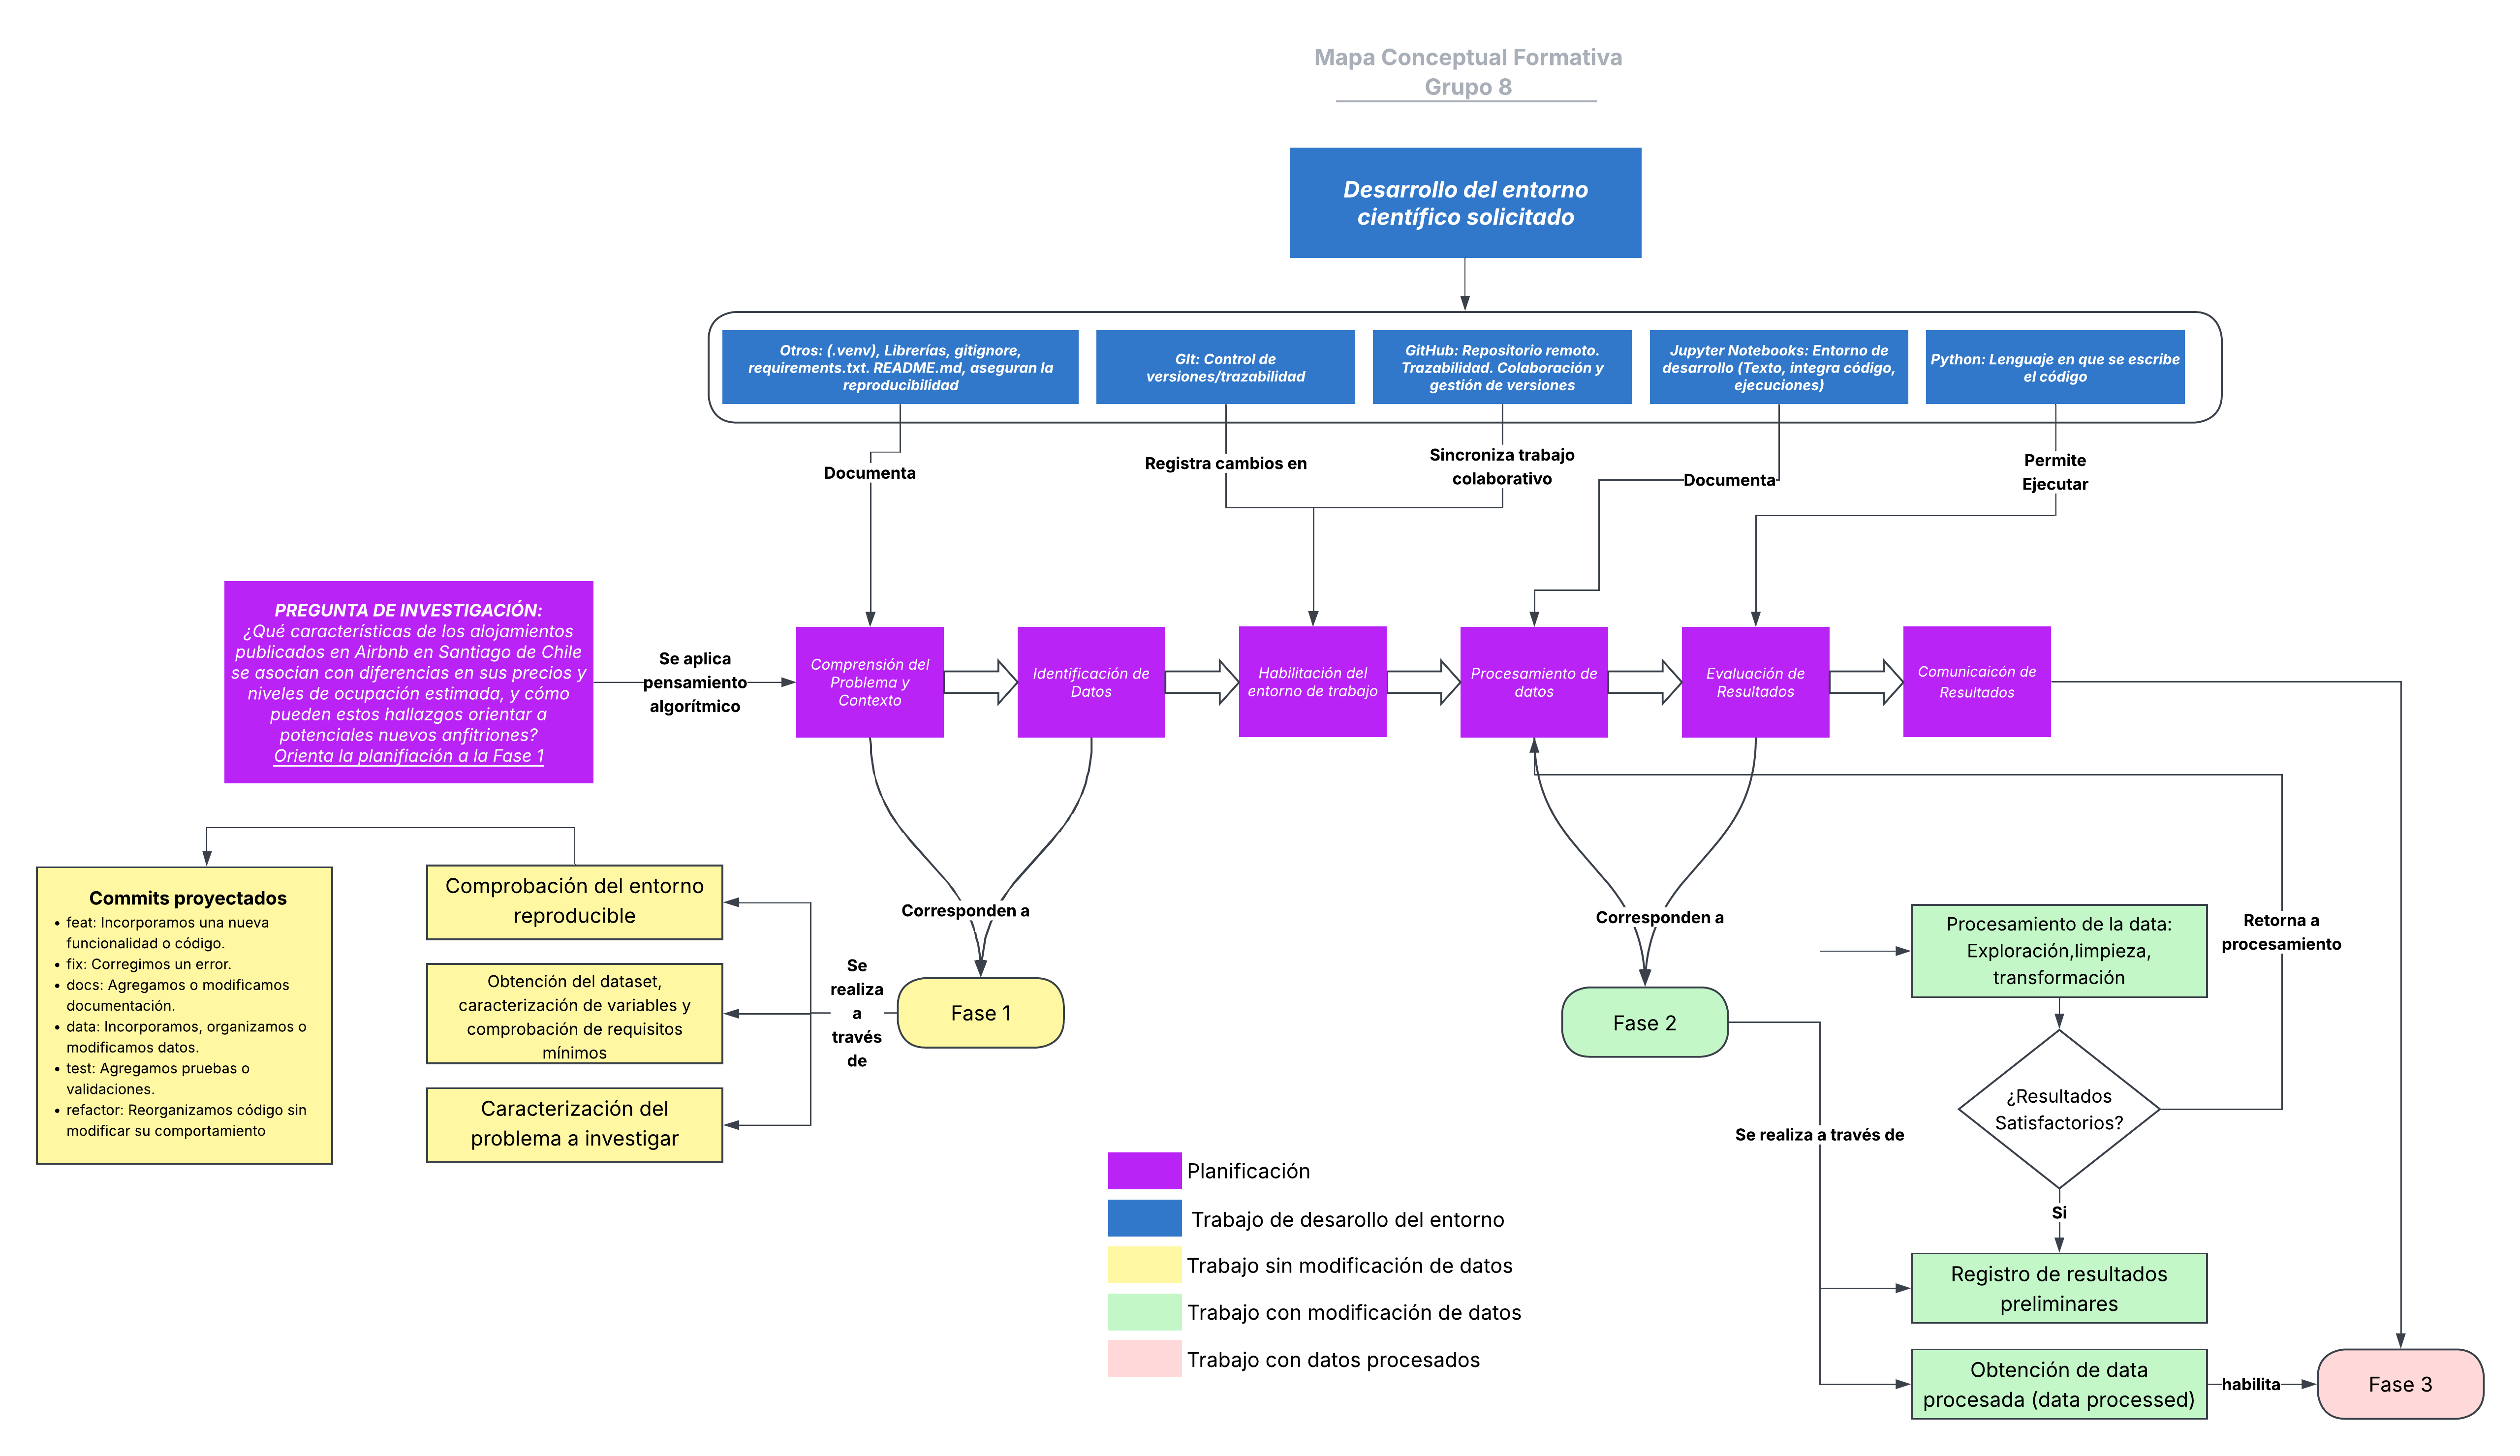

In [39]:
from IPython.display import display, Image

ruta_imagen = RAIZ / "docs" / "mapa_conceptual.png"


display(Image(filename=str(ruta_imagen)))

## 9. Persistencia y trazabilidad

El resultado debe quedar guardado y documentado. Esta sección produce los artefactos que se
versionan en el repositorio y se citan en el informe técnico.

In [40]:
def generar_readme(config, ficha, requisitos, ruta):
    """Escribe el README tecnico del repositorio a partir de la configuracion."""
    integrantes = "\n".join(f"- {n} (@usuario-github)" for n in config["integrantes"])
    dependencias = "\n".join(f"- {r}" for r in requisitos)

    contenido = f"""# {config['titulo']} — {config['grupo']}

{config['problematica']}

## Integrantes
{integrantes}

## Datos
- Fuente: {ficha['titulo']} ({ficha['autor']}, {ficha['plataforma']})
- Enlace: {ficha['url']}
- Estructura: {ficha['filas']} filas x {ficha['columnas']} columnas
- Ubicación esperada: `data/raw/`

## Estructura del repositorio
```
data/raw/        datos originales, sin modificar
data/processed/  datos tras limpieza y transformación (F2)
docs/            diccionario, fichas y metadatos
src/             módulos reutilizables del proyecto
F1/ F2/ F3/ F4/  cuadernos e informes de cada fase
```

## Requisitos y ejecución
Python 3.13

    python -m venv .venv
    source .venv/Scripts/activate    # Windows, Git Bash
    # source .venv/bin/activate      # macOS y Linux
    python -m pip install -r requirements.txt

Ejecutar los cuadernos en orden, F1 y luego F2. Cada cuaderno localiza la raíz del
proyecto aunque Jupyter lo abra en su propia carpeta.

### Dependencias declaradas
{dependencias}

## Convención de commits
Prefijos usados: docs, data, feat, fix.

## Decisiones técnicas
- Los datos son comunes a todas las fases (`data/`); los cuadernos se separan por fase.
- Semilla aleatoria fijada en {SEMILLA} para asegurar reproducibilidad.
- Registro breve de las decisiones relevantes y su motivo, actualizado al cerrar cada fase.
"""
    ruta.write_text(contenido, encoding="utf-8")
    return contenido


ARCHIVO_README = DIR_DOCS / "README_F1_borrador.md"

# Recuperamos las dependencias desde el archivo existente
requisitos = [
    linea.strip()
    for linea in (RAIZ / "requirements.txt").read_text(encoding="utf-8").splitlines()
    if linea.strip() and not linea.lstrip().startswith("#")
]

# Generamos el borrador
contenido = generar_readme(PROYECTO, FICHA, requisitos, ARCHIVO_README)

print(f"{ARCHIVO_README} escrito ({len(contenido.splitlines())} líneas)\n")
print("\n".join(contenido.splitlines()[:14]), "\n...")

c:\Users\Xheis\OneDrive\Escritorio\grupo_8_magister_mcdi500\docs\README_F1_borrador.md escrito (153 líneas)

# Caracterización de alojamientos Airbnb en Santiago de chile — Grupo 8

Las personas que evalúan incorporarse como anfitriones a plataformas de alojamiento temporal necesitan conocer las características de la oferta existente. Sin embargo, la información sobre ubicación, precios publicados, tipos de alojamiento, capacidad y disponibilidad se encuentra distribuida entre numerosos anuncios. Este proyecto busca organizar y describir dichas características mediante datos públicos de Airbnb en Santiago de Chile.

## Integrantes
- Giuliano Garces (@usuario-github)
- Ana Hermosilla (@usuario-github)
- Cristopher Contreras (@usuario-github)
- Gabriel Cruz (@usuario-github)

## Datos
- Fuente: Inside Airbnb - Santiago, Chile (Murray Cox (Inside Airbnb), Inside Airbnb)
- Enlace: https://data.insideairbnb.com/chile/rm/santiago/2026-09-23/data/listings.csv.gz
- Estructura: 18904 filas x 90

In [41]:
#El diccionario ya se había creado en la sección 5.3
diccionario.to_csv(DIR_DOCS / "diccionario_variables.csv", index=False)
evaluacion.to_csv(DIR_DOCS / "evaluacion_criterios_dataset.csv", index=False)
vinculacion.to_csv(DIR_DOCS / "vinculacion_mapa_conceptual.csv", index=False)

# Metadatos de la fase: lo que permite reconstruir en qué condiciones se ejecutó.
METADATOS = {
    "proyecto": PROYECTO["titulo"],
    "grupo": PROYECTO["grupo"],
    "fase": "F1",
    "fecha_ejecucion": date.today().isoformat(),
    "semilla": SEMILLA,
    "python": sys.version.split()[0],
    "sistema": f"{platform.system()} {platform.release()}",
    "interprete": ENTORNO["interprete"],
    "entorno_virtual": ENTORNO["entorno_virtual"],
    "dependencias": ENTORNO["versiones"],
    "dataset": {"titulo": FICHA["titulo"], "url": FICHA["url"],
                "archivo_descargado": ARCHIVO.exists()},
}
(DIR_DOCS / "metadatos_fase1.json").write_text(
    json.dumps(METADATOS, indent=2, ensure_ascii=False), encoding="utf-8")

for archivo in sorted(DIR_DOCS.iterdir()):
    print(f"  {archivo.as_posix():48} {archivo.stat().st_size:6} bytes")

  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/anotaciones_preliminares_ia.csv  14888 bytes
  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/diccionario_variables.csv  18390 bytes
  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/diccionario_variables_generado_f1.csv  14885 bytes
  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/evaluacion_criterios_dataset.csv    798 bytes
  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/mapa_conceptual.png 712456 bytes
  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/metadatos_fase1.json    695 bytes
  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/README_F1_borrador.md   4325 bytes
  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/validacion_dataset.md   6116 bytes
  c:/Users/Xheis/OneDrive/Escritorio/grupo_8_magister_mcdi500/docs/vinculacion_mapa_conceptual.csv   1025 bytes


In [42]:
# Resumen de cierre: qué existía al empezar y qué queda al terminar la fase.
resumen = pd.DataFrame([
    {"artefacto": "Carpetas del proyecto",
     "estado": len([p for p in RAIZ.rglob("*") if p.is_dir() and ".git" not in p.parts])},
    {"artefacto": "Archivos en docs/", "estado": len(list(DIR_DOCS.iterdir()))},
    {"artefacto": "Dependencias declaradas", "estado": len(requisitos)},
    {"artefacto": "Variables en el diccionario", "estado": len(diccionario)},
    {"artefacto": "Nodos del mapa vinculados", "estado": len(vinculacion)},
    {"artefacto": "Criterios de dataset incumplidos", "estado": len(incumplidos)},
])
resumen

,artefacto,estado
0,Carpetas del proyecto,3269
1,Archivos en docs/,9
2,Dependencias declaradas,108
3,Variables en el diccionario,90
4,Nodos del mapa vinculados,9
5,Criterios de dataset incumplidos,0


## Conclusiones y trazabilidad

La fase deja operativo un entorno verificado, una estructura de repositorio con sus
artefactos de reproducibilidad (`.gitignore`, `requirements.txt`, `README.md`), un módulo
propio importable y la documentación del conjunto de datos con su evaluación contra los
criterios del curso. Cada paso se implementó como una función documentada y verificada
(`presentar_proyecto`, `verificar_entorno`, `escribir_requirements`, `evaluar_criterios`,
`git`, `validar_fase1`, `generar_readme`).

**Trazabilidad con el repositorio (F1):** este cuaderno se ubica en la carpeta `F1/`; el
`README` documenta dependencias e instrucciones de ejecución; los archivos de `docs/`
sostienen las tablas del informe técnico, y el historial de *commits* refleja el avance
descrito en él.

---

## 10. Reflexión técnica

Este apartado es obligatorio en la entrega. Redáctenlo con **sus** decisiones y cifras.

### Hallazgos

- **El conjunto docente no sirve como conjunto de proyecto.** La evaluación de la sección
  5.2 lo muestra sin ambigüedad: faltan variable de fecha, variable discreta y una de alta
  cardinalidad. Descubrirlo aquí, y no en la Fase 2, es precisamente para lo que sirve
  evaluar el conjunto antes de comprometerse con él.

- **El rol analítico, y no el tipo de dato, es lo que define el trabajo pendiente.** En el
  diccionario hay cuatro variables `int64` que son cosas distintas: un identificador, tres
  binarias y una objetivo. El preprocesamiento de la Fase 2 se deriva de esa declaración.

- **La reproducibilidad es verificable o no existe.** El `requirements.txt` de este
  cuaderno se generó a partir de las versiones realmente presentes en el entorno, no de
  una lista escrita de memoria.

### Dificultades y cómo se resolvieron

- **Rutas.** Se usaron rutas relativas con `pathlib` y se acordó una única convención de
  carpetas de datos, compartida con el cuaderno de la Fase 2.

- **Dependencia del archivo de datos.** El cuaderno no falla si el conjunto todavía no
  está descargado: informa qué falta y continúa, porque la Fase 1 no depende de él.

### Decisiones que quedan abiertas

- Cuál será el conjunto definitivo del proyecto, una vez que supere los criterios.
- Si el conjunto se versiona en el repositorio o solo se documenta su descarga.
- Si el módulo `src/utilidades.py` crecerá o si parte de él pasará a clases en la Fase 3.

> **Declarar lo que queda abierto evidencia más dominio que presentar todo resuelto.** En
> esta fase no debería estarlo.

---

## 11. Verificación antes de entregar

**Cuaderno**

- Corre completo tras *Kernel → Restart Kernel and Run All Cells*, sin errores.
- La numeración de ejecución es continua.
- Cada bloque de código está precedido por una celda narrativa que explica su lógica.
- Todas las rutas son relativas y la semilla está declarada.

**Contenido técnico**

- La problemática, los objetivos, el alcance y las limitaciones están declarados.
- El entorno se verifica con evidencia (intérprete, entorno virtual, versiones).
- La procedencia del conjunto está documentada, con enlace y cita en APA 7.
- El diccionario declara el rol analítico de cada variable.
- El conjunto candidato fue evaluado contra los criterios del curso.
- Hay pruebas de casos normales, límite y excepciones.

**Archivos**

- `.gitignore` y `requirements.txt` en la raíz, ambos con contenido.
- `README.md` técnico, generado desde la configuración del proyecto.
- `docs/` con diccionario, evaluación del conjunto, vinculación y metadatos.
- `src/utilidades.py` importable.

**Repositorio**

- Carpeta F1 con este cuaderno, *commits* de todos los integrantes y `README` actualizado.
- El correo de Git coincide con el de la cuenta de GitHub.

---

*Cuaderno de la Fase 1 · MCDI500 · Magíster en Ciencia de Datos e Inteligencia
Artificial · Universidad Andrés Bello*